# Pythonでたどる楕円曲線・保型形式・L関数

整数や分数で解く方程式から、複素関数のFourier係数が現れ、その係数から作ったL関数が再び有理点の構造を語る。このつながりを、定義、数式の導出、厳密計算、数値実験の順にたどる。

中心に置くのは次の二つである。

$$E:y^2+y=x^3-x^2-10x-20,$$
$$f(\tau)=\eta(\tau)^2\eta(11\tau)^2
=q\prod_{m\ge1}(1-q^m)^2(1-q^{11m})^2,\qquad q=e^{2\pi i\tau}.$$

一方は有理数係数の三次方程式、もう一方は複素上半平面上の無限積である。この両者を独立に計算すると、有限体上の点数から得る整数と、無限積の展開係数が一致する。後半では、その同じ整数列を使ってL関数の中心値や中心付近の零点を調べる。

ここで使う用語・記号・定理の内容は、使用する箇所で説明する。大きな定理については「何を保証する定理として使うか」を明示し、有限計算や数値近似でその定理自体を証明したとは扱わない。

実験の共通処理は `module.py` に集約した。図と実行結果を含む実験は `analysis.ipynb` 一つにまとまっている。

|節|取り組む問い|
|:--|:--|
|0|記号、計算環境、厳密計算と近似の区別|
|1|有理数の三角形や平方和を、方程式・級数へどう変換するか|
|2|楕円曲線の点を足すとは何か。有限位数・高さ・還元は何を表すか|
|3|2降下法でランクを決めるには何を列挙するか|
|4|複素格子と保型曲線は楕円曲線をどう分類するか|
|5|保型形式の係数を作り、Hecke作用素をどう計算するか|
|6|L関数を収束域の外でどう評価するか|
|7|L関数の零点と有理点のランク、BSD公式をどう読み分けるか|
|8|射影空間、p進数、Frey曲線を具体的に計算する|
|9–10|規約・誤差・テストを確認し、結論の範囲を整理する|

## 0. 記号と、読み進めるための準備

必要なのは、分数の計算、多項式、微分・積分と級数、行列の積・固有値についての初歩である。専門用語は次の意味で使う。

|記号・用語|この解説での意味|
|:--|:--|
|$\mathbb Z,\mathbb Q,\mathbb R,\mathbb C$|整数、有理数、実数、複素数の集合|
|$\mathbb F_p$|素数$p$を法とする剰余の体。非零元では割り算もできる|
|$E(K)$|座標を$K$に取った曲線$E$の点。楕円曲線では無限遠点$O$も含める|
|群、部分群|足し算と逆元を持つ集合、およびその演算で閉じた部分集合|
|準同型、核、像|演算を保つ写像、単位元へ移る元の集合、実際に移る先の集合|
|$G/H$|$H$の元だけ違うものを同じとみなす商群。例は$\mathbb Z/2\mathbb Z$|
|$nP$|座標に$n$を掛ける操作ではなく、点$P$の群演算による$n$倍|
|torsion、位数|ある正整数$n$で$nP=O$になる点と、その最小の$n$|
|ランク$r$|有理点の群に含まれる、独立な無限位数の方向の数|
|$\mathbb H$|$\operatorname{Im}\tau>0$を満たす複素数$\tau$の集合|
|$q=e^{2\pi i\tau}$|Fourier展開をべき級数として書くための変数。$\tau\in\mathbb H$なら$\vert q\vert <1$|
|$[q^n]f$、$O(q^{M+1})$|$q^n$の係数、および$M$次より後を表示していないこと|
|$\#S$、$\vert G\vert $|有限集合・有限群の元の個数|
|$\operatorname{ord}_{s=1}L$|$s=1$における零点の次数。最初に非零となるTaylor項の次数|

**同じ文字の使い分けに注意する。** Weierstrass方程式の$a_1,a_2,\ldots$は曲線を指定する係数であり、L関数の係数$a_n$とは別物である。コードでは前者を `curve.ainvs`、後者を `l_coefficients` の配列として扱う。$\Delta_E$は曲線の判別式、$\Delta_q$は正規化した保型形式である。

例えば$O(q^{11})$までしか分からない係数列に対して、$q^{20}$の係数を勝手に0と置いてはいけない。以下の実装では、多項式として切った計算と、未知の係数が必要になる計算を分ける。

### 0.1 実行環境と計算の役割分担

`Fraction`は既約分数を保った群演算、SymPyは記号式の恒等変形・素因数分解・行列計算、NumPyとSciPyは有限集合の計数や数値求積、mpmathは多倍長の複素関数評価、pandasは表、Matplotlibは図に使う。

`module.py` と `analysis.ipynb` を同じディレクトリへ置き、`requirements.txt` のパッケージを導入してから、Pythonカーネルで上から順に実行する。セルを飛ばすと、前の節で定義した曲線や係数配列が存在しないことがある。

近似値の末尾が変わる可能性はあるが、整数・分数の等式を検査する部分は許容誤差を使わない。最初にパッケージのバージョンと回帰テスト結果を出力する。

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m ipykernel install --user --name elliptic-lab --display-name "Python (elliptic-lab)"
jupyter lab analysis.ipynb
```

Jupyterで `Python (elliptic-lab)` を選択し、カーネルを再起動して全セルを実行する。主要な回帰チェックだけを実行するには `python module.py` を使う。図はノートブックの出力へ保存される。

In [1]:
from pathlib import Path
import sys, platform, importlib.metadata as metadata
from fractions import Fraction as F
from itertools import product
import math
import numpy as np
import pandas as pd
import sympy as sp
import mpmath as mp
import matplotlib.pyplot as plt
from IPython.display import display, Math
assert Path("module.py").is_file(), "module.py と同じフォルダで開いてください。"
import module as lab

mp.mp.dps = 60
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.precision", 10)
versions = {name: metadata.version(name) for name in
            ["sympy", "numpy", "scipy", "pandas", "mpmath", "matplotlib", "nbformat", "nbclient"]}
display(pd.DataFrame({"package": ["Python"] + list(versions),
                      "version": [platform.python_version()] + list(versions.values())}))
print(lab.run_self_tests())

,package,version
0,Python,3.13.5
1,sympy,1.14.0
2,numpy,2.3.5
3,scipy,1.17.0
4,pandas,2.2.3
5,mpmath,1.3.0
6,matplotlib,3.10.8
7,nbformat,5.10.4
8,nbclient,0.10.4


{'tests': 366, 'status': 'PASS', 'seconds': 0.122}


### 0.2 何を計算し、どの定理を使うのか

学習の流れは次のとおりである。

$$\text{有理数の問題}\longrightarrow E(\mathbb Q)
\longrightarrow\#E(\mathbb F_p)\longrightarrow a_p\longrightarrow a_n
\longrightarrow\begin{cases}f(\tau)=\sum a_nq^n,\\ L(E,s)=\sum a_nn^{-s}.\end{cases}$$

これとは別に、複素格子から保型形式を導入し、$\eta$積を展開する経路を作る。最後に二つの経路の整数列を比較する。

|結論|根拠の種類|この実験で行うこと|
|:--|:--|:--|
|点が曲線上にある、点の和が指定点である|整数・分数の恒等式|厳密に計算する|
|有限体の点数、mod 8の障害|有限集合の全列挙|指定集合をすべて調べる|
|係数が400次まで一致する|形式的級数の係数計算|丸めなしで比較する|
|有理点の群が有限生成である|Mordell–Weilの定理|定理の内容を述べて使う|
|torsionの候補が15種類に限られる|Mazurの定理|候補の列挙と還元を組み合わせる|
|降下写像の核が$2E(\mathbb Q)$である|2降下法の定理|仕組みと逆構成の計算例を説明する|
|全$E/\mathbb Q$が保型形式に対応する|保型性定理|正確な主張を述べて使う|
|$L(E,1)$がある値に近い|誤差を伴う数値計算|打切り・求積・丸めを区別する|
|一般のBSD公式|予想としての命題|具体例を調べ、一般の証明とは区別する|

有限範囲で点が見つからないことは不存在の証明にはならない。一方、すべての有理解が満たすはずの合同条件に解がないことは、不存在を示せる。この差が第3節の要点になる。

## 1. 合同数を楕円曲線の有理点へ変換する

正整数$n$を面積とする直角三角形で、三辺がすべて有理数になるものが存在するとき、$n$を**合同数**という。$(3,4,5)$から6は合同数だと分かる。整数辺に限らないので、5にも可能性がある。

対応する方程式は

$$E_n:y^2=x^3-n^2x=x(x-n)(x+n)$$

である。$P=(x,y)\in E_n(\mathbb Q)$で$y\ne0$なら、符号つきの数

$$a=\frac{x^2-n^2}{y},\qquad b=\frac{2nx}{y},\qquad c=\frac{x^2+n^2}{y}$$

を作る。分母を払えば

$$(x^2-n^2)^2+(2nx)^2=(x^2+n^2)^2$$

なので$a^2+b^2=c^2$である。また

$$\frac{ab}{2}=\frac{nx(x^2-n^2)}{y^2}=n$$

となる。$y\ne0$だから$x=0,\pm n$でもなく、辺の長さとして$|a|,|b|,|c|$を取れば、面積$n$の非退化な直角三角形になる。

逆に、$a^2+b^2=c^2$、$ab/2=n>0$を満たす符号つき有理数から

$$x=\frac{nb}{c-a},\qquad y=\frac{2n^2}{c-a}$$

を作れる。$c-a=0$なら$b=0$となって面積が0になるので、分母は0でない。代入すると$y^2=x^3-n^2x$を満たし、上の変換と互いに逆になる。まずこの代入をSymPyで検査する。

In [2]:
x, y, n = sp.symbols("x y n", nonzero=True)
a, b, c = (x*x-n*n)/y, 2*n*x/y, (x*x+n*n)/y
curve_equation = y*y-x**3+n*n*x
assert sp.factor(a*a+b*b-c*c) == 0
assert sp.factor((a*b/2-n) + n*curve_equation/y**2) == 0
display(Math(r"a^2+b^2-c^2=" + sp.latex(sp.factor(a*a+b*b-c*c))))
display(Math(r"ab/2-n=" + sp.latex(sp.factor(a*b/2-n))))
X = sp.Symbol("X")
assert sp.expand((X-5)*X*(X+5)) == X**3-25*X

<IPython.core.display.Math object>

<IPython.core.display.Math object>

$x=-4,y=6,n=5$では、符号つきの三辺は$(-3/2,-20/3,41/6)$になる。長さだけを残せば$(3/2,20/3,41/6)$で、面積は5である。

ただし、絶対値を取る処理は符号の情報を捨てる。したがって正の三辺から逆変換しても、初めの点$(-4,6)$に戻るとは限らない。`positive=False` を付けた変換について往復を検査し、長さの表示は別に行う。

さらに、差が5の三数の積を平方にする問題

$$y^2=x(x+5)(x+10)$$

で$X=x+5$と置くと、$y^2=X^3-25X$になる。このように、見かけの違う有理数の問題が同じ曲線へ移る。点を2倍、3倍とする操作は次節で定義するが、生成された点から異なる三角形を作れることを先に観察しておく。

図は$E_5$の実数の点の形を示す。図上のほとんどの点は有理点ではないため、滑らかな線が見えることと、有理点を見つけることは別である。

In [3]:
E5 = lab.EllipticCurve(a4=-25)
P5 = E5.point(-4, 6)
signed_triangle = lab.congruent_triangle(5, P5, positive=False)
positive_triangle = lab.congruent_triangle(5, P5)
assert lab.triangle_to_point(5, *signed_triangle) == P5
print("符号つき:", signed_triangle)
print("辺長として表示:", positive_triangle)
print("正の辺を逆写像に入れた点:", lab.point_text(lab.triangle_to_point(5, *positive_triangle)))
rows = []
for k in range(1, 5):
    Q = E5.mul(k, P5)
    A, B, C = lab.congruent_triangle(5, Q)
    assert A*A + B*B == C*C and A*B/2 == 5
    rows.append({"k": k, "kP": lab.point_text(Q), "a": str(A), "b": str(B), "c": str(C), "area": str(A*B/2)})
display(pd.DataFrame(rows))

符号つき: (Fraction(-3, 2), Fraction(-20, 3), Fraction(41, 6))
辺長として表示: (Fraction(3, 2), Fraction(20, 3), Fraction(41, 6))
正の辺を逆写像に入れた点: (25/4, 75/8)


,k,kP,a,b,c,area
0,1,"(-4, 6)",3/2,20/3,41/6,5
1,2,"(1681/144, -62279/1728)",1519/492,4920/1519,3344161/747348,5
2,3,"(-2439844/5094049, 39601568754/11497268593)",25353117/3525434,35254340/25353117,654686219104361/89380740677778,5
3,4,"(11183412793921/2234116132416, 1791076534232245919/3339324446657665536)",535583225279/4998504070056,49985040700560/535583225279,249850594047271558364480641/2677114931410801046145624,5


,x,y
0,-10,0
1,-9,6
2,-9,-6
3,-5,0
4,0,0
5,40,300
6,40,-300


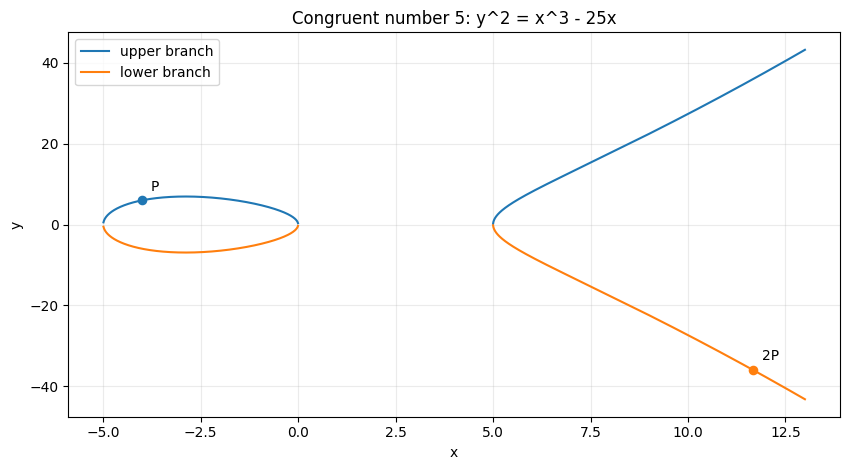

In [4]:
P10 = lab.EllipticCurve(0, 15, 0, 50, 0)
points_in_window = lab.integral_points_short(P10, -10, 50)
display(pd.DataFrame([{"x": int(P[0]), "y": int(P[1])} for P in points_in_window]))
# この表は探索区間内の整数点だけ。全有理点を列挙した表ではない。
lab.plot_real_curve(E5, points={"P": P5, "2P": E5.mul(2, P5)},
                    title="Congruent number 5: y^2 = x^3 - 25x")
plt.show()

### 1.1 Tunnellの条件を有限の個数へ落とす

$n$は正の平方因子を持たない整数とする。平方因子を持つ$n=d^2m$は、三角形の各辺を$d$倍・$1/d$倍することで$m$の問題へ帰着できる。ここでは帰着の混同を避けるため、実装への入力を平方因子なしに制限する。

奇数$n$について

$$A_n=\#\{(x,y,z)\in\mathbb Z^3:n=2x^2+y^2+32z^2\},$$
$$B_n=\#\{(x,y,z)\in\mathbb Z^3:n=2x^2+y^2+8z^2\}$$

と置く。Tunnellの定理が与える必要条件は「$n$が合同数なら$2A_n=B_n$」である。偶数$n$では

$$C_n=\#\{(x,y,z):n/2=4x^2+y^2+32z^2\},$$
$$D_n=\#\{(x,y,z):n/2=4x^2+y^2+8z^2\}$$

を使い、必要条件は$2C_n=D_n$になる。[TUNNELL](https://link.springer.com/article/10.1007/BF01389327)どちらも符号・順序を指定どおり区別して数える。例えば項$32z^2$があれば$|z|\le\sqrt{n/32}$なので、無限集合に見えても必要な探索範囲は有限である。

**等式が不成立なら非合同数と確定する。成立した場合の逆向きにはBSDの仮定を置く。** この計算はTunnellの定理自体の証明ではなく、その条件の厳密な適用である。例えば$n=2$では$C_2=D_2=2$なので、必要条件$4=2$が失敗する。表の `passes=True` を無条件の合同数認定として読まない。

In [5]:
results = [lab.tunnell_test(n) for n in range(1, 36)
           if all(e == 1 for e in sp.factorint(n).values())]
tunnell = pd.DataFrame(results)
tunnell["読み方"] = tunnell["passes"].map({False: "必要条件を満たさないので非合同数", True: "必要条件成立。逆向きはBSDを仮定"})
display(tunnell)

,n,A,B,passes,読み方
0,1,2,2,False,必要条件を満たさないので非合同数
1,2,2,2,False,必要条件を満たさないので非合同数
2,3,4,4,False,必要条件を満たさないので非合同数
3,5,0,0,True,必要条件成立。逆向きはBSDを仮定
4,6,0,0,True,必要条件成立。逆向きはBSDを仮定
5,7,0,0,True,必要条件成立。逆向きはBSDを仮定
6,10,4,4,False,必要条件を満たさないので非合同数
7,11,4,12,False,必要条件を満たさないので非合同数
8,13,0,0,True,必要条件成立。逆向きはBSDを仮定
9,14,0,0,True,必要条件成立。逆向きはBSDを仮定


### 1.2 平方和の個数を、べき級数の係数として数える

$$\Theta(q)=\sum_{m\in\mathbb Z}q^{m^2}=1+2q+2q^4+2q^9+\cdots$$

と置く。$q^{m^2}$を$k$個掛けて指数を足せば、

$$[q^n]\Theta(q)^k
=\#\{(m_1,\ldots,m_k)\in\mathbb Z^k:m_1^2+\cdots+m_k^2=n\}
=:S_k(n).$$

これは形式的な積の定義だけから分かる。$q^M$まで欲しければ$|m|\le\lfloor\sqrt M\rfloor$だけを扱えばよい。$n=0$の係数は常に1で、以下の約数公式は$n\ge1$について使う。

Jacobiの四平方公式は

$$S_4(n)=8\sum_{d\mid n,\,4\nmid d}d.$$

例えば$n=4$では$8(1+2)=24$。四つの$\pm1$から16通り、一つの$\pm2$と三つの0から8通りで、直接数えても24になる。次のセルは、$\Theta^4$の積と約数公式を80次まで別々に計算する。$\Theta^6,\Theta^8$も展開し、平方の数を増やすと表現数がどう変わるかを見る。[SQUARES](https://dlmf.nist.gov/27.13)

,n,S4: 畳み込み,S4: 約数和,S6,S8
0,1,8,8,12,16
1,2,24,24,60,112
2,3,32,32,160,448
3,4,24,24,252,1136
4,5,48,48,312,2016
5,6,96,96,544,3136
6,7,64,64,960,5504
7,8,24,24,1020,9328
8,9,104,104,876,12112
9,10,144,144,1560,14112


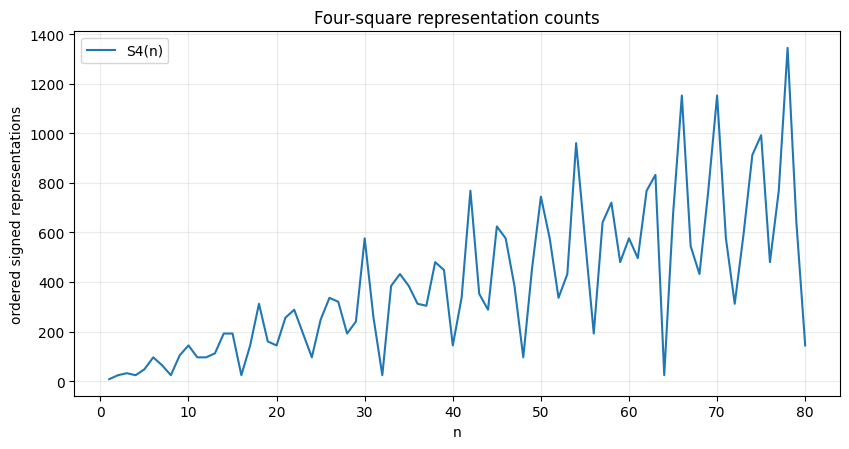

In [6]:
M_theta = 80
S4 = lab.theta_power(4, M_theta)
S6 = lab.theta_power(6, M_theta)
S8 = lab.theta_power(8, M_theta)
four_square_formula = [0] + [8*sum(int(d) for d in sp.divisors(n) if d % 4) for n in range(1, M_theta+1)]
assert S4[1:] == four_square_formula[1:]
assert S4[4] == 24 and S6[4] == 252
rows = [{"n": n, "S4: 畳み込み": S4[n], "S4: 約数和": four_square_formula[n],
         "S6": S6[n], "S8": S8[n]} for n in range(1, 21)]
display(pd.DataFrame(rows))
lab.plot_lines(range(1, M_theta+1), {"S4(n)": S4[1:]},
               "Four-square representation counts", "n", "ordered signed representations")
plt.show()

### 1.3 Dirichlet指標と、三平方・L級数への入口

三平方については、平方数がmod 8で$0,1,4$のいずれかになることから、$n\equiv7\pmod8$を三つの平方で表せない。これは有限個の剰余の検査だけで証明できる。$\Theta^3$の係数でも確かめる。

一方、二平方の個数には

$$\chi_{-4}(m)=\begin{cases}0&m\equiv0,2\pmod4,\\1&m\equiv1\pmod4,\\-1&m\equiv3\pmod4\end{cases},
\qquad S_2(n)=4\sum_{d\mid n}\chi_{-4}(d)$$

という公式がある。$\chi_{-4}$は周期4で、$\chi_{-4}(ab)=\chi_{-4}(a)\chi_{-4}(b)$を満たす。一般に、このような周期的な乗法性を持ち、法と互いに素でない整数で0になる関数をDirichlet指標という。[SQUARES](https://dlmf.nist.gov/27.13) [CHAR](https://doc.sagemath.org/html/en/reference/modfrm/sage/modular/dirichlet.html)

そのL級数は

$$L(s,\chi)=\sum_{n\ge1}\frac{\chi(n)}{n^s}.$$

$\chi_{-4}$の場合、$s=1$では$1-1/3+1/5-\cdots=\pi/4$となる。$1/(1+x^2)$の幾何級数を$0\le x<1$で積分し、交代級数の収束を使って$x=1$へ近づければ、$\arctan1=\pi/4$が得られる。打切り誤差の絶対値は、次の非零項以下である。

また$\operatorname{Re}s>1$で和の順を交換すれば、二平方公式から

$$\sum_{n\ge1}\frac{S_2(n)}{n^s}
=4\sum_{d,m\ge1}\frac{\chi_{-4}(d)}{(dm)^s}
=4\zeta(s)L(s,\chi_{-4})$$

と分かる。整数の表現数とL級数が接続する最初の例である。

実装 `dirichlet_character_partial(D,N)` は、負の**基本判別式**$D$から作る二次指標$\chi_D(n)=(D/n)$を扱う。基本判別式とは、平方因子のない$D\equiv1\pmod4$、または$D=4d$で平方因子のない$d\equiv2,3\pmod4$のものをいう。この条件なら指標の周期に$|D|$を使える。任意の負整数を周期配列にしてよいわけではないため、例えば$D=-5$は拒否し、対応する基本判別式$-20$を用いる。

In [7]:
S3 = lab.theta_power(3, 80)
assert all(S3[n] == 0 for n in range(7, 81, 8))
S2 = lab.theta_power(2, 80)
assert all(S2[n] == 4*sum(int(sp.kronecker_symbol(-4, d)) for d in sp.divisors(n))
           for n in range(1, 81))
display(pd.DataFrame([{"n": n, "S2(n)": S2[n], "S3(n)": S3[n]} for n in (3, 5, 7, 11, 15)]))
beta_rows = []
for terms in (10, 100, 1000, 10000):
    partial = lab.dirichlet_character_partial(-4, terms)
    bound = 1/(terms+1)  # termsは偶数。次の非零項の大きさ。
    assert abs(partial-math.pi/4) <= bound
    beta_rows.append({"項数": terms, "L(1,chi_-4)部分和": partial,
                      "pi/4との差": abs(partial-math.pi/4), "交代級数の尾の上界": bound})
display(pd.DataFrame(beta_rows))

,n,S2(n),S3(n)
0,3,0,8
1,5,8,24
2,7,0,0
3,11,0,24
4,15,0,0


,項数,"L(1,chi_-4)部分和",pi/4との差,交代級数の尾の上界
0,10,0.8349206349,0.0495224715,0.0909090909
1,100,0.7803986631,0.0049995002,0.0099009901
2,1000,0.7848981639,0.0004999995,0.0009990010
3,10000,0.7853481634,0.0000500000,0.0000999900


## 2. 楕円曲線の方程式と群構造

楕円曲線は、指定した原点$O$を持つ、滑らかな射影的な種数1の曲線である。ここでは有理数体上で

$$y^2+a_1xy+a_3y=x^3+a_2x^2+a_4x+a_6$$

という一般Weierstrass形を使う。「滑らか」とは、方程式とすべての偏微分が同時に0になる特異点を持たないこと。「射影的」は無限遠点を含めることを意味する。種数は複素数上で見たコンパクトな曲面の穴の数として理解でき、楕円曲線では1になる。名称に反して、平面の楕円そのものではない。

係数から次を作る。

$$\begin{aligned}
b_2&=a_1^2+4a_2,&b_4&=a_1a_3+2a_4,&b_6&=a_3^2+4a_6,\\
b_8&=a_1^2a_6+4a_2a_6-a_1a_3a_4+a_2a_3^2-a_4^2,\\
c_4&=b_2^2-24b_4,&c_6&=-b_2^3+36b_2b_4-216b_6,\\
\Delta_E&=-b_2^2b_8-8b_4^3-27b_6^2+9b_2b_4b_6.
\end{aligned}$$

$\Delta_E\ne0$が滑らかさの条件である。これらは

$$c_4^3-c_6^2=1728\Delta_E,\qquad j(E)=\frac{c_4^3}{\Delta_E}$$

を満たす。$j$は複素数上の同型類を分類する不変量だが、同じ$j$でも有理数上で同型とは限らない。

有理数体では

$$X=x+\frac{b_2}{12},\quad Y=y+\frac{a_1x+a_3}{2}$$

により$Y^2=X^3+AX+B$へ移せ、$A=-c_4/48,B=-c_6/864$になる。短い形の判別式は$-16(4A^3+27B^2)$。ただし2や3を法とする計算ではこの分母を使えないので、一般形を保持する必要がある。[ECAPI](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/ell_rational_field.html)

In [8]:
E11 = lab.E11
invariants = E11.invariants()
display(pd.DataFrame([{"不変量": key, "厳密値": str(value)} for key, value in invariants.items()]))
assert invariants["discriminant"] == -11**5
assert invariants["c4"]**3-invariants["c6"]**2 == 1728*invariants["discriminant"]
short, transform = E11.short_model()
T11 = E11.point(5, 5)
assert short.contains(transform(T11))
assert short.invariants()["discriminant"] == invariants["discriminant"]
print("短い方程式の係数 A, B:", short.a4, short.a6)
print("点の変換:", lab.point_text(T11), "->", lab.point_text(transform(T11)))

,不変量,厳密値
0,b2,-4
1,b4,-20
2,b6,-79
3,b8,-21
4,c4,496
5,c6,20008
6,discriminant,-161051
7,j,-122023936/161051


短い方程式の係数 A, B: -31/3 -2501/108
点の変換: (5, 5) -> (14/3, 11/2)


### 2.1 無限遠点を加える理由

射影座標$[X:Y:Z]$は、非零の$\lambda$を掛けた$[\lambda X:\lambda Y:\lambda Z]$と同じ点を表す。ただし$[0:0:0]$は点ではない。$Z\ne0$なら$x=X/Z,y=Y/Z$として普通の座標へ戻れる。

短い形を三次の同次式にすると

$$Y^2Z=X^3+AXZ^2+BZ^3.$$

$Z=0$では$X=0$となり、残る点は$O=[0:1:0]$一つである。この$O$を点の足し算の零元にする。有限座標では垂直線の交点が消えるように見える場合でも、射影平面では$O$を含めて扱える。

次のセルでは$O$における偏微分を調べる。三次Weierstrass曲線では$\partial F/\partial Z(O)=1$で滑らかである。一方、四次方程式をそのまま射影平面へ閉じると、アフィン部分が滑らかでも無限遠点が特異になる場合がある。「方程式の次数」と「滑らかな曲線の種数」を単純に同一視しない。

In [9]:
X, Y, Z, A, B = sp.symbols("X Y Z A B")
F_cubic = Y**2*Z-X**3-A*X*Z**2-B*Z**3
F_quartic = Y**2*Z**2-X**4-Z**4
at_O = {X: 0, Y: 1, Z: 0}
cubic_gradient = [sp.diff(F_cubic, t).subs(at_O) for t in (X, Y, Z)]
quartic_gradient = [sp.diff(F_quartic, t).subs(at_O) for t in (X, Y, Z)]
assert cubic_gradient == [0, 0, 1]
assert quartic_gradient == [0, 0, 0]
display(pd.DataFrame({"曲線": ["短いWeierstrass三次曲線", "四次曲線の平面射影閉包"],
                      "Oでの勾配": [str(cubic_gradient), str(quartic_gradient)]}))

,曲線,Oでの勾配
0,短いWeierstrass三次曲線,"[0, 0, 1]"
1,四次曲線の平面射影閉包,"[0, 0, 0]"


### 2.2 点の足し算を座標で導く

短い形なら、2点を通る直線と曲線の第三交点を取り、その$y$座標の符号を反転した点を和とする。同じ点を足す場合は接線を使う。一般形では反転が

$$-(x,y)=(x,-y-a_1x-a_3)$$

になる。これは方程式を$y$の二次方程式と見たとき、二つの根の和が$-a_1x-a_3$になるためである。

$P=(x_1,y_1)$、$Q=(x_2,y_2)$について、垂直線になる場合を除き、直線を$y=\lambda x+\nu$と書く。

$$\lambda=\begin{cases}
(y_2-y_1)/(x_2-x_1)&x_1\ne x_2,\\
(3x_1^2+2a_2x_1+a_4-a_1y_1)/(2y_1+a_1x_1+a_3)&P=Q,
\end{cases}\qquad\nu=y_1-\lambda x_1.$$

直線を曲線へ代入し、三次式の根の和を比較すると、第三交点の$x$座標、したがって和の$x$座標は

$$x_3=\lambda^2+a_1\lambda-a_2-x_1-x_2.$$

最後に一般形の反転を行えば

$$P+Q=(x_3,-(\lambda+a_1)x_3-\nu-a_3).$$

$Q=-P$なら和は$O$、$P+O=P$。倍点の分母が0になる場合も$2P=O$として扱う。この幾何学的演算が結合則を満たすことは楕円曲線の群法則の定理であり、以下の有限テストは一般の結合則の証明ではない。

実装は整数と`Fraction`で計算する。$E_5:y^2=x^3-25x$、$Q=(-4,6)$では接線の傾きが$23/12$、和は

$$2Q=\left(\frac{1681}{144},-\frac{62279}{1728}\right).$$

図では接線上の第三交点と、その反転後の$2Q$を区別する。もう一つの例$y^2=x^3+1$、$P=(2,3)$では6回足すと$O$に戻る。

2Q = (1681/144, -62279/1728)


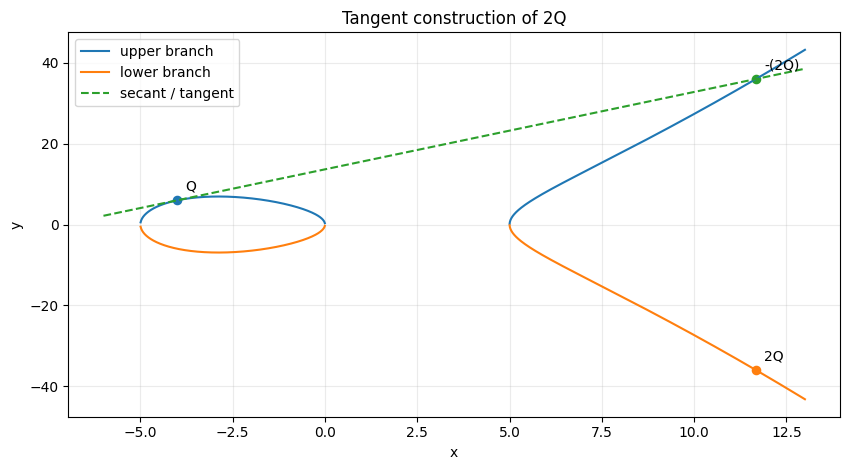

,n,nP
0,0,O
1,1,"(2, 3)"
2,2,"(0, 1)"
3,3,"(-1, 0)"
4,4,"(0, -1)"
5,5,"(2, -3)"
6,6,O


In [10]:
Q = E5.point(-4, 6)
double_Q = E5.mul(2, Q)
assert double_Q == (F(1681, 144), F(-62279, 1728))
print("2Q =", lab.point_text(double_Q))
lab.plot_real_curve(E5, points={"Q": Q, "2Q": double_Q, "-(2Q)": E5.neg(double_Q)},
                    line=(23/12, 41/3), title="Tangent construction of 2Q")
plt.show()
E6tors = lab.EllipticCurve(a6=1)
P6 = E6tors.point(2, 3)
display(pd.DataFrame([{"n": k, "nP": lab.point_text(E6tors.mul(k, P6))} for k in range(7)]))
assert E6tors.mul(6, P6) is None
assert E11.neg(T11) == E11.point(5, -6)

### 2.3 有理点の群、ランク、15種類のtorsion

Mordell–Weilの定理は、有理点の群が有限生成であることを保証する。有限生成アーベル群の構造定理と合わせると

$$E(\mathbb Q)\simeq E(\mathbb Q)_{\rm tors}\oplus\mathbb Z^r.$$

有限群の部分がtorsion、$r$がランクである。$r=0$なら有理点はすべて有限位数で個数も有限。$r>0$なら無限個になる。生成元の選び方は一般に一意ではない。

Mazurの定理により、$E(\mathbb Q)_{\rm tors}$は次の15種類のいずれかである。

$$\mathbb Z/m\mathbb Z\quad(1\le m\le10\text{ または }m=12),$$
$$\mathbb Z/2\mathbb Z\oplus\mathbb Z/(2m)\mathbb Z\quad(1\le m\le4).$$

表の `ainvs` は$(a_1,a_2,a_3,a_4,a_6)$、`generators` は実際に足して調べる点を示す。まず生成元の位数と生成部分群の大きさを正確に数える。さらに全torsionの位数の候補

$$1,2,3,4,5,6,7,8,9,10,12,16$$

を、第2.5節で説明する良い還元の単射で絞る。確認した部分群の位数だけが残れば、それが全torsionである。**生成元の検査だけで完全性を宣言せず、余分なtorsionが存在しないことも確認する。** この15例では43以下の良い素数を使うと、すべて単一の候補になる。[MAZUR](https://link.springer.com/article/10.1007/BF02684339) [ECAPI](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/ell_rational_field.html)

In [11]:
torsion_examples = pd.DataFrame(lab.verify_torsion_examples())
display(torsion_examples)

,group,ainvs,generators,generator_orders,generated_order,total_order_candidates,completeness
0,trivial,"(0, 0, 0, 0, -2)",[],[],1,[1],Mazur + 良い還元の単射で確定
1,Z/2,"(0, 0, 0, 0, 8)","[(-2, 0)]",[2],2,[2],Mazur + 良い還元の単射で確定
2,Z/3,"(0, 0, 0, 0, 4)","[(0, 2)]",[3],3,[3],Mazur + 良い還元の単射で確定
3,Z/4,"(0, 0, 0, 4, 0)","[(2, 4)]",[4],4,[4],Mazur + 良い還元の単射で確定
4,Z/5,"(0, -1, -1, 0, 0)","[(0, 1)]",[5],5,[5],Mazur + 良い還元の単射で確定
5,Z/6,"(0, 0, 0, 0, 1)","[(2, 3)]",[6],6,[6],Mazur + 良い還元の単射で確定
6,Z/7,"(0, 0, 0, -43, 166)","[(3, 8)]",[7],7,[7],Mazur + 良い還元の単射で確定
7,Z/8,"(7, 0, 0, 16, 0)","[(-2, 10)]",[8],8,[8],Mazur + 良い還元の単射で確定
8,Z/9,"(1, -1, 1, -14, 29)","[(3, 1)]",[9],9,[9],Mazur + 良い還元の単射で確定
9,Z/10,"(1, 0, 0, -45, 81)","[(0, 9)]",[10],10,[10],Mazur + 良い還元の単射で確定


### 2.4 無限位数を有限個の候補の排除で示す

整数$A,B$に対する$y^2=x^3+Ax+B$を考える。Nagell–Lutzの定理によれば、有限位数のアフィン有理点は整数座標を持ち、$y=0$でなければ$y^2$が$4A^3+27B^2$を割る。$y=0$の点は位数2である。

$y^2=x^3-2$なら$4A^3+27B^2=108$なので、有限位数かもしれない点の$|y|$は$1,2,3,6$に限られる。それぞれ$x^3=y^2+2$は$3,6,11,38$で、整数の立方ではない。$y=0$でも$x^3=2$に有理数解はない。したがって全torsionは$\{O\}$である。

ところが$(3,5)$は曲線上にあるため、これは無限位数の点と分かる。従うのは$r\ge1$までで、$r=1$という上限を証明するには別の情報が必要である。座標を少し探索しただけで全有理点を分類したことにしない。

In [12]:
y_candidates = [y for y in range(1, 11) if 108 % (y*y) == 0]
assert y_candidates == [1, 2, 3, 6]
display(pd.DataFrame([{"|y|": y, "必要な x^3": y*y+2,
                      "整数の立方か": bool(sp.integer_nthroot(y*y+2, 3)[1])}
                     for y in y_candidates]))
assert not any(sp.integer_nthroot(y*y+2, 3)[1] for y in y_candidates)
Eminus2 = lab.EllipticCurve(a6=-2)
assert Eminus2.contains(Eminus2.point(3, 5))
print("torsion は O のみ。(3,5) は非零点なので無限位数。したがって rank >= 1。")

,|y|,必要な x^3,整数の立方か
0,1,3,False
1,2,6,False
2,3,11,False
3,6,38,False


torsion は O のみ。(3,5) は非零点なので無限位数。したがって rank >= 1。


### 2.5 有限体上で点を数える

素数$p$を法として係数を還元する。得られた三次曲線が滑らかなら、$E$はそのモデルで$p$における**良い還元**を持つ。滑らかな還元曲線の点数には無限遠点を1つ加え、

$$N_p=\#E(\mathbb F_p),\qquad a_p=p+1-N_p$$

と置く。$a_p$はFrobeniusのトレースと呼ばれるが、ここではこの点数との差として計算できる。

総当たりなら$p^2$組の$(x,y)$を調べる。奇素数なら各$x$について$y$の二次方程式の判別式

$$D_x=(a_1x+a_3)^2+4(x^3+a_2x^2+a_4x+a_6)$$

を使える。Legendre記号$\chi_p(t)$を、$t=0$なら0、非零の平方なら1、非平方なら$-1$と定義すると、対応する$y$の個数は$1+\chi_p(D_x)$である。したがって

$$N_p=1+\sum_{x\in\mathbb F_p}(1+\chi_p(D_x)).$$

平方剰余を事前に表にしておけば、点数計算のループを$O(p^2)$から$O(p)$に減らせる。$p=2$は別に全列挙する。次のセルは両方式の一致を確認する。$y^2=x^3+3$では$N_5=6,N_7=13$になる。

In [13]:
Eplus3 = lab.EllipticCurve(a6=3)
assert Eplus3.count_mod_p(5) == 6 and Eplus3.count_mod_p(7) == 13
display(pd.DataFrame([{"p": p, "全点列挙": len(E11.points_mod_p(p)),
                      "平方剰余表": E11.count_mod_p(p), "このモデルは滑らか": E11.smooth_mod_p(p)}
                     for p in (2, 3, 5, 7, 11, 13, 17, 19)]))
print("y^2=x^3+3 の F7 上の点:", Eplus3.points_mod_p(7))

,p,全点列挙,平方剰余表,このモデルは滑らか
0,2,5,5,True
1,3,5,5,True
2,5,5,5,True
3,7,10,10,True
4,11,11,11,False
5,13,10,10,True
6,17,20,20,True
7,19,20,20,True


y^2=x^3+3 の F7 上の点: [None, (1, 2), (1, 5), (2, 2), (2, 5), (3, 3), (3, 4), (4, 2), (4, 5), (5, 3), (5, 4), (6, 3), (6, 4)]


#### torsionを絞れる理由

良い素数$p$で、$m$が$p$と互いに素なら、位数が$m$を割る有理点をmod $p$へ送る写像は単射である。したがって、全torsionの位数を$T$とすると、$T$の$p$以外の素数からなる部分は$N_p$を割る。

$y^2=x^3+3$の例では5以外・7以外の素数位数は$\gcd(6,13)=1$で排除でき、5の位数は$N_7=13$、7の位数は$N_5=6$から排除できる。第2.3節の実装も同じ原理をすべての候補位数へ適用している。**$p$自身の部分まで無条件に単射だと仮定する必要はない。**

### 2.6 最小モデルと悪い還元

有理数上で同型な方程式でも、mod $p$での見かけは変わる。例えば$y^2=x^3+5^6$はmod 5で特異だが、$(x,y)=(5^2X,5^3Y)$で$Y^2=X^3+1$へ変換すると5で滑らかになる。

その素数で判別式の$p$進付値をこれ以上下げられない整数係数モデルを**局所最小モデル**という。最小モデルで判別式を割る素数が、曲線の本当の悪い還元の素数になる。

特異点を原点へ移して方程式の最低次の二次部分を見ると、二つの異なる接線がある**節点**か、重なった接線を持つ**尖点**かを区別できる。節点なら乗法的還元、尖点なら加法的還元。二本の接線が$\mathbb F_p$上で定義できる場合を分裂乗法的還元という。

次のセルは、尖点、分裂・非分裂節点、導手11の曲線の特異点の接線を計算する。ここでは局所分類の仕組みを見る。任意の入力から最小モデル・導手・Tamagawa数を算出するTateアルゴリズムは実装していない。

In [14]:
nonminimal = lab.EllipticCurve(a6=5**6)
minimal_example = lab.EllipticCurve(a6=1)
print("元のモデル / 変換後の mod 5 の滑らかさ:", nonminimal.smooth_mod_p(5), minimal_example.smooth_mod_p(5))
reduction_examples = [("additive example", lab.EllipticCurve(a4=35, a6=5), 5),
                      ("split example", lab.EllipticCurve(a2=-1, a6=35), 5),
                      ("nonsplit example", lab.EllipticCurve(a2=-1, a6=35), 7),
                      ("11a1", E11, 11)]
rows = []
for name, E, p in reduction_examples:
    singular = E.singular_points_mod_p(p)
    slopes = [E.tangent_slopes_mod_p(p, P) for P in singular]
    rows.append({"例": name, "p": p, "特異点": str(singular), "Fp内の接線の傾き": str(slopes),
                 "射影三次曲線の点数": E.count_mod_p(p)})
display(pd.DataFrame(rows))

元のモデル / 変換後の mod 5 の滑らかさ: False True


,例,p,特異点,Fp内の接線の傾き,射影三次曲線の点数
0,additive example,5,"[(0, 0)]",[[0]],6
1,split example,5,"[(0, 0)]","[[2, 3]]",5
2,nonsplit example,7,"[(0, 0)]",[[]],9
3,11a1,11,"[(5, 5)]","[[5, 6]]",11


### 2.7 Hasse境界と拡大体

有限体$\mathbb F_q$上の楕円曲線の点数は、Hasseの定理により

$$|\#E(\mathbb F_q)-(q+1)|\le2\sqrt q$$

を満たす。$q=p$では$|a_p|\le2\sqrt p$である。これは$p+1$を中心に、点数の揺れが平方根程度に抑えられることを意味する。

素数$p$の場合、$2\sqrt p$が整数でないため端の等号は起こらない。しかし$q$が平方数なら等号はあり得る。$\mathbb F_{25}=\mathbb F_5[u]/(u^2-2)$を使い、$y^2=x^3+1$を数えると

$$\#E(\mathbb F_{25})=36=25+1+2\sqrt{25}$$

となる。$a+bu$を$(a,b)$で持ち、$u^2=2$として掛け算すれば、この拡大体を直接実装できる。図は導手11の曲線の$p\le1000$での$a_p$と、両側のHasse境界を示す。特定範囲の検査と一般の定理を区別して読む。

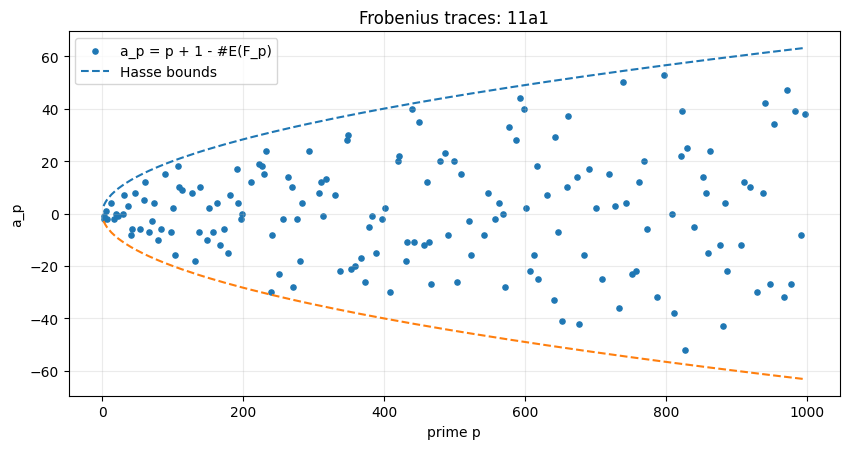

F25 の直接計数: 36 = 25+1+2 sqrt(25)


In [15]:
for p in sp.primerange(2, 1001):
    p = int(p)
    if p != 11:
        assert lab.CURVES["11a1"].ap(p)**2 <= 4*p
lab.plot_hasse(lab.CURVES["11a1"], 1000)
plt.show()
N25 = lab.count_fp2_short(0, 1, p=5, nonresidue=2)
assert N25 == 25 + 1 + 2*5 == 36
print("F25 の直接計数:", N25, "= 25+1+2 sqrt(25)")

### 2.8 有理数の大きさを測る高さ

既約分数$x=m/n$、$n>0$について

$$h(x)=\log\max(|m|,n)$$

とする。実数としての絶対値が小さくても、分子と分母が大きければ高さは大きい。例えば$1000001/1000000$は1に近いが、高さは約$\log10^6$である。

楕円曲線の標準高さを

$$\widehat h(P)=\frac12\lim_{k\to\infty}\frac{h(x(2^kP))}{4^k},\qquad\widehat h(O)=0$$

で定義する。前の$1/2$を付ける規約を一貫して使う。標準高さの定理は

$$\widehat h(mP)=m^2\widehat h(P),\quad\widehat h(P)\ge0,\quad
\widehat h(P)=0\Longleftrightarrow P\text{ はtorsion}$$

を保証する。また平行四辺形則$\widehat h(P+Q)+\widehat h(P-Q)=2\widehat h(P)+2\widehat h(Q)$を満たす。

コードでは倍点と座標は有理数で厳密に計算し、最後の対数だけ近似する。倍点を増やすと数値近似は安定しやすいが、分子・分母は急激に巨大化する。表にはそのビット長も載せる。打切り深さの比較は収束の観察であり、残りの誤差を保証する証明ではない。

,n,half_height,full_height,bits
0,0,0.5493061443,1.0986122887,2
1,1,0.6074765505,1.2149531011,8
2,2,0.6741815963,1.3483631926,32
3,3,0.6741835645,1.3483671290,125
4,4,0.6742147819,1.3484295638,499
5,5,0.6745475718,1.3490951436,1994
6,6,0.6747755904,1.3495511808,7975
7,7,0.6747768047,1.3495536094,31900


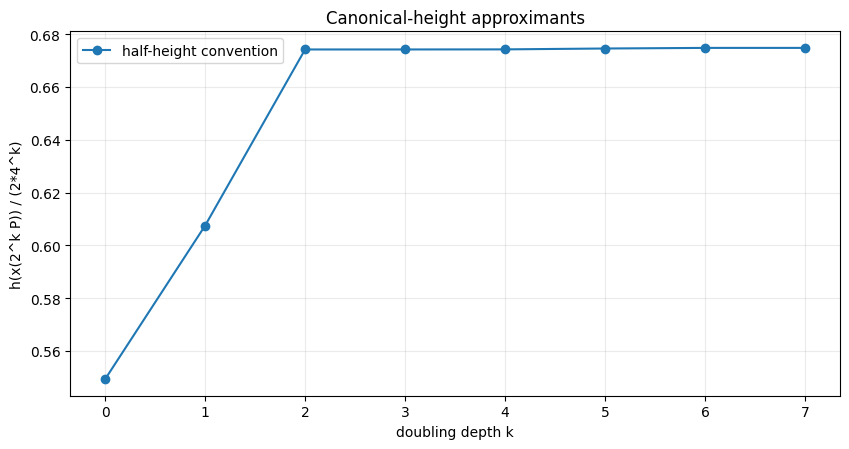

,m,近似 hhat(mP),m^2 hhat(P)
0,1,0.6745475718,0.6747755904
1,2,2.6991023616,2.6991023616
2,3,6.0729932115,6.0729803137
3,4,10.7964288752,10.7964094466


In [16]:
Eheight = lab.EllipticCurve(a6=-2)
Pheight = Eheight.point(3, 5)
height_table = pd.DataFrame(lab.height_sequence(Eheight, Pheight, depth=7))
display(height_table)
lab.plot_lines(height_table["n"], {"half-height convention": height_table["half_height"]},
               "Canonical-height approximants", "doubling depth k", "h(x(2^k P)) / (2*4^k)", markers=True)
plt.show()
hP = lab.height_sequence(Eheight, Pheight, 6)[-1]["half_height"]
display(pd.DataFrame([{"m": m, "近似 hhat(mP)": lab.height_sequence(Eheight, Eheight.mul(m, Pheight), 5)[-1]["half_height"],
                      "m^2 hhat(P)": m*m*hP} for m in range(1, 5)]))

### 2.9 高さ行列から関係を予想し、厳密演算へ戻す

ここでは高さ対を

$$\langle P,Q\rangle=\widehat h(P+Q)-\widehat h(P)-\widehat h(Q)$$

と定義する。これはtorsionを除いた空間で正定値対称双線形形式となり、対角成分は$\langle P,P\rangle=2\widehat h(P)$になる。文献・ソフトウェアによって高さ対の前に$1/2$を置くこともあるため、定義を省略して行列式だけ比較してはいけない。

点$P_1,\ldots,P_r$の高さ行列を$H_{ij}=\langle P_i,P_j\rangle$とする。厳密な$\det H$が非零なら、これらの点はtorsionを除いて独立である。$H\boldsymbol n=0$という整数関係が見つかれば、$\sum n_iP_i$はtorsionになる。

具体例は

$$E:y^2=x^3+2308x^2+665858x,$$
$$P=(-1681,25543),\quad Q=(-338,26),\quad
R=(332929/36,-215405063/216).$$

近似高さ行列の核は$(1,1,-1)$という関係を示唆する。そこで数値の小ささをゼロと決めつけず、群演算で

$$P+Q-R=(0,0),\qquad2(0,0)=O$$

を確認する。これは線形従属の厳密な確認である。

比較用に$P_3=(577/16,332929/64)$へ入れ替えると行列式は正の値に見えるが、この実装は高さ近似の保証誤差を持たない。その数値だけで独立性を証明したとはしない。「近似で候補を見つけ、証明可能な演算へ戻す」という使い方が重要である。

「torsionを除いて独立」とは、$n_1,\ldots,n_r$がすべて0ではない整数の組について、$n_1P_1+\cdots+n_rP_r$がtorsionになる関係が存在しないことをいう。ゼロ係数だけの自明な関係は除く。


In [17]:
E2308 = lab.EllipticCurve(a2=2308, a4=665858)
P = E2308.point(-1681, 25543)
Q = E2308.point(-338, 26)
R = E2308.point(F(332929, 36), F(-215405063, 216))
relation = E2308.add(E2308.add(P, Q), E2308.neg(R))
assert relation == E2308.point(0, 0) and E2308.mul(2, relation) is None
Hdependent = lab.height_pairing_matrix(E2308, [P, Q, R], depth=5)
P3 = E2308.point(F(577, 16), F(332929, 64))
Hindependent = lab.height_pairing_matrix(E2308, [P, Q, P3], depth=5)
print("P+Q-R =", lab.point_text(relation))
display(pd.DataFrame(Hdependent, index=["P", "Q", "R"], columns=["P", "Q", "R"]))
display(pd.DataFrame({"行列": ["P,Q,R", "P,Q,P3"],
                      "近似行列式": [np.linalg.det(Hdependent), np.linalg.det(Hindependent)]}))
print("行列式は有限深さの近似。P+Q-R=(0,0)の関係は別の厳密演算で確定。")

P+Q-R = (0, 0)


,P,Q,R
P,7.3969664674,-3.6017962324,3.7951708935
Q,-3.6017962324,6.2637283084,2.6619320340
R,3.7951708935,2.6619320340,6.4571033717


,行列,近似行列式
0,"P,Q,R",-0.0000057448
1,"P,Q,P3",101.8498193801


行列式は有限深さの近似。P+Q-R=(0,0)の関係は別の厳密演算で確定。


## 3. 2降下法を平方類の有限問題として扱う

$$E:y^2=(x-e_1)(x-e_2)(x-e_3),\qquad e_1,e_2,e_3\in\mathbb Z$$

で根が相異なる場合を考える。$(e_i,0)$の三点と$O$がすべて有理2-torsionなので、一般の曲線より降下法が扱いやすい。

非零有理数$a,b$について$a/b$が有理数の平方なら同じ**平方類**とする。例えば$12$と3は同じ類で、$-12$と$-3$も同じだが、3と$-3$は異なる。各類は符号つき平方因子なし整数で代表させられる。乗算後に平方を除くので、各元の2乗は単位元になる。

$y\ne0$では

$$\delta(P)=(x-e_1,x-e_2,x-e_3)\in(\mathbb Q^\times/\mathbb Q^{\times2})^3$$

と定義する。$\delta(O)=(1,1,1)$。$T_i=(e_i,0)$では0の平方類を作らないように、$i$番目の成分を$(e_i-e_j)(e_i-e_k)$、残る$j,k$番目をそれぞれ$e_i-e_j,e_i-e_k$とする。例えば

$$\delta(T_1)=((e_1-e_2)(e_1-e_3),e_1-e_2,e_1-e_3).$$

三成分の積は常に平方類1である。2降下法の定理は、この写像が群準同型で、その核がちょうど$2E(\mathbb Q)$であることを保証する。したがって像は$E(\mathbb Q)/2E(\mathbb Q)$と同型になる。

準同型である理由の中心は直線の交点にある。$P,Q,R$が同じ直線$y=\lambda x+\nu$上にあれば、曲線との差の三次式を$x=e_i$で評価することにより

$$(x(P)-e_i)(x(Q)-e_i)(x(R)-e_i)=(\lambda e_i+\nu)^2$$

を得る。平方類では積が1で、$R=-(P+Q)$だから$\delta(P+Q)=\delta(P)\delta(Q)$となる。無限遠点や2-torsionには上の例外式が対応する。

像の平方因子なし代表に現れる素数は、根の差$(e_1-e_2)(e_2-e_3)(e_1-e_3)$を割るものに限られる。理由は、$x-e_i$の分母に奇数の$p$進付値があれば三成分の積が平方にならず、分子に奇数の付値があれば他の成分にも$p$が現れて、根の差を割る必要があるからである。これで無限個の平方類から有限個の候補へ落ちる。

最初の例では$(e_1,e_2,e_3)=(6,20,-26)$を使い、具体的な点について準同型性と平方類の生成を確認する。

In [18]:
roots = (6, 20, -26)
Ed = lab.EllipticCurve(a4=-556, a6=3120)
Pd, Qd = Ed.point(-8, 84), Ed.point(24, 60)
Td1, Td2 = Ed.point(6, 0), Ed.point(20, 0)
rows = [{"点": label, "座標": lab.point_text(P), "delta": str(lab.descent_delta(roots, P))}
        for label, P in [("O", None), ("T1", Td1), ("T2", Td2), ("P", Pd), ("Q", Qd),
                         ("P+Q", Ed.add(Pd, Qd)), ("2P", Ed.mul(2, Pd))]]
display(pd.DataFrame(rows))
assert lab.descent_delta(roots, Ed.add(Pd, Qd)) == lab.square_class_product(lab.descent_delta(roots, Pd), lab.descent_delta(roots, Qd))
span = lab.square_class_span([lab.descent_delta(roots, P) for P in (Td1, Td2, Pd, Qd)])
assert len(span) == 16
print("この4点の像が生成する平方類の個数:", len(span))

,点,座標,delta
0,O,O,"(1, 1, 1)"
1,T1,"(6, 0)","(-7, -14, 2)"
2,T2,"(20, 0)","(14, 161, 46)"
3,P,"(-8, 84)","(-14, -7, 2)"
4,Q,"(24, 60)","(2, 1, 2)"
5,P+Q,"(-247/16, -5733/64)","(-7, -7, 1)"
6,2P,"(745/36, -4715/216)","(1, 1, 1)"


この4点の像が生成する平方類の個数: 16


### 3.1 核に入る点を実際に2で割る

$e_1+e_2+e_3=0$とし、$E:y^2=x^3+Ax+B$と書く。$Q=(x_Q,y_Q)$、$y_Q\ne0$で$\delta(Q)=(1,1,1)$なら、各$x_Q-e_i$に有理平方根$t_i$がある。

三点$(e_i,t_i)$を通る二次の補間多項式を

$$p(X)=a+bX+cX^2=\sum_{i=1}^3t_i\prod_{j\ne i}\frac{X-e_j}{e_i-e_j}$$

とする。$x_Q-X-p(X)^2$は各$e_i$で消えるので、$X^3+AX+B$で割った余りは0である。係数を比較すると

$$2ac+b^2-Ac^2=0,\quad2ab-Bc^2-2Abc=-1,\quad a^2-2bcB=x_Q.$$

$c=0$なら最初の式から$b=0$となり、二番目に反する。したがって$c\ne0$である。最初の二式から

$$(b/c)^3+A(b/c)+B=(1/c)^2$$

が従うため、$P=(b/c,1/c)$は曲線上の有理点になる。倍点公式へ代入すると$x(2P)=x_Q$となり、必要なら$P$の符号を変えて$2P=Q$を得られる。

このセルでは、既知の点の2倍を入力して、その半分を補間で復元する。半分は2-torsionを加えた分だけ複数存在し得るので、初めの点と同じ座標を返すことではなく、2倍が入力に一致することを検査する。$Q$が2-torsionの場合の一般処理はこの補間関数の対象外である。

In [19]:
Qdouble = Ed.mul(2, Pd)
recovered_half = lab.half_point_by_interpolation(Ed, roots, Qdouble)
assert Ed.mul(2, recovered_half) == Qdouble
print("与えた Q:", lab.point_text(Qdouble))
print("構成した半分:", lab.point_text(recovered_half))
print("2倍の厳密一致:", Ed.mul(2, recovered_half) == Qdouble)

与えた Q: (745/36, -4715/216)
構成した半分: (502/9, -10304/27)
2倍の厳密一致: True


### 3.2 合同数34のランクを64候補で確定する

$$E_{34}:y^2=x(x+34)(x-34)$$

で根を$(0,-34,34)$の順に取る。根の差を割る素数は2と17なので、成分の候補は

$$G=\{\pm1,\pm2,\pm17,\pm34\}.$$

三成分の積が平方になるため、最初の二成分$(d_1,d_2)\in G^2$を選べば第三成分の類も決まり、候補は$8^2=64$通りである。

候補に対応する**被覆曲線**を射影座標$[X:Y:Z:W]$で

$$C(d_1,d_2):\quad
 d_2Y^2-d_1X^2=34W^2,\qquad
 d_2Y^2-d_1d_2Z^2=68W^2$$

と書く。$W\ne0$の部分で$W=1$とすれば、点

$$x=d_1X^2,\qquad y=d_1d_2XYZ$$

を$E_{34}$へ戻せる。射影形にしておくことで、無限遠点に対応する場合も落とさない。平方類の類を変えない平方因子は座標へ吸収する。

まず

$$T_1=(0,0),\quad T_2=(-34,0),\quad P=(-16,-120),\quad Q=(-2,-48)$$

を使う。各点を0回または1回加える16通りを作り、得られた平方類がすべて異なることを確認する。各行には有理点という具体的な証人があるため、少なくとも16類が像に入る。

In [20]:
E34 = lab.EllipticCurve(a4=-34**2)
roots34 = (0, -34, 34)
points34 = [E34.point(0, 0), E34.point(-34, 0), E34.point(-16, -120), E34.point(-2, -48)]
witnesses34 = {}
for bits in product((0, 1), repeat=4):
    point = None
    for bit, generator in zip(bits, points34):
        if bit:
            point = E34.add(point, generator)
    witnesses34[lab.descent_delta(roots34, point)] = point
image34 = set(witnesses34)
assert len(image34) == 16
display(pd.DataFrame([{"delta": str(delta), "有理点の証人": lab.point_text(point)}
                      for delta, point in sorted(witnesses34.items())]))

,delta,有理点の証人
0,"(-34, 2, -17)","(-34, 0)"
1,"(-34, 34, -1)","(-306/25, 13872/125)"
2,"(-17, 2, -34)","(-4352/961, 2136288/29791)"
3,"(-17, 34, -2)","(-272/9, 2312/27)"
4,"(-2, 2, -1)","(-2, -48)"
5,"(-2, 34, -17)","(-28322/1089, -4013632/35937)"
6,"(-1, 2, -2)","(-16, -120)"
7,"(-1, 34, -34)","(0, 0)"
8,"(1, 1, 1)",O
9,"(1, 17, 17)","(289/4, -4335/8)"


#### 残りの候補を、実数とmod 8で排除する

$d_2<0$の32候補は、上の二式の符号から実数の射影点さえ存在しない。$d_1>0$なら第一式、$d_1<0$なら第二式を見れば、左辺が非正、右辺が非負となり、等号には座標がすべて0であることが必要になる。これは射影点ではない。

次に$C(1,2)$を考える。二番目を2で割ると

$$2Y^2-X^2=34W^2,\qquad Y^2-Z^2=34W^2.$$

有理点があれば分母を払い、整数座標の共通の2の因子を取り除いて、少なくとも一つが奇数である解を取れるはずである。しかしmod 8の平方は$0,1,4$しかない。

$W$が奇数なら第二式は$Y^2-Z^2\equiv2$となり不可能。$W$が偶数なら第二式から$Y^2\equiv Z^2$、第一式から$X^2\equiv2Y^2$となる。$Y$が奇数では右辺2が平方でないため、$Y$は偶数。すると$Z$も偶数で、第一式から$X$も偶数となり、全座標が偶数という矛盾が出る。

これは$8^4$通りの列挙でも確認できる。さらに、$\delta(E)$は部分群である。$C(1,2)$に対応する像の外の類へ、既知の像16元を掛けた剰余類16個もすべて像の外になる。もし積が像に入れば、既知の元の逆元を掛けて$C(1,2)$の類も像に入ってしまうためである。

In [21]:
assert lab.primitive_obstruction_count(34, 8) == 0
G0 = [-34, -17, -2, -1, 1, 2, 17, 34]
all64 = {(a, b, lab.square_class(a*b)) for a, b in product(G0, repeat=2)}
real_excluded = {d for d in all64 if d[1] < 0}
obstruction_coset = {lab.square_class_product((1, 2, 2), d) for d in image34}
assert len(real_excluded) == 32 and len(obstruction_coset) == 16
assert not (image34 & real_excluded or image34 & obstruction_coset or real_excluded & obstruction_coset)
assert image34 | real_excluded | obstruction_coset == all64
print("64候補 = 有理点による証人16 + 実数で排除32 + 2進障害の剰余類16")
print("完全有理2-torsionの条件で |E(Q)/2E(Q)| = 2^(r+2) = 16。したがって r=2。")
classification = [("有理点を構成", len(image34)), ("実数で排除", len(real_excluded)), ("2進障害で排除", len(obstruction_coset))]
display(pd.DataFrame(classification, columns=["分類", "個数"]))

64候補 = 有理点による証人16 + 実数で排除32 + 2進障害の剰余類16
完全有理2-torsionの条件で |E(Q)/2E(Q)| = 2^(r+2) = 16。したがって r=2。


,分類,個数
0,有理点を構成,16
1,実数で排除,32
2,2進障害で排除,16


これで「有理点のある16類」「実数で不可能な32類」「2進で不可能な16類」が互いに重ならず64候補すべてを覆う。したがって像の位数は正確に16である。

完全な有理2-torsionを持つ場合、Mordell–Weilの分解から

$$E(\mathbb Q)/2E(\mathbb Q)\simeq(\mathbb Z/2\mathbb Z)^{r+2}$$

なので、$2^{r+2}=16$、すなわち**$r=2$**と確定する。数値的にランクを推定したのではなく、明示した定理と全候補の有限分類を組み合わせた結論である。

ただし、商$E/2E$の生成元を得たことから、全$E(\mathbb Q)$の生成元を得たとは限らない。例えば$\mathbb Z$の中の$3\mathbb Z$はmod 2では全体を生成するが、指数は3である。同様に、奇数指数の不足は2で割った商だけでは検出できない。基底の完全性を確認する作業を**飽和**という。

### 3.3 p進数と、局所的に解けることの意味

有理数$a$の分子・分母に現れる$p$の指数の差を$v_p(a)$と書く。$v_2(40)=3$、$v_2(3/8)=-3$である。$|a|_p=p^{-v_p(a)}$という距離で$\mathbb Q$を完備化したものが$\mathbb Q_p$。整数に相当する部分$\mathbb Z_p$の元は、mod $p,p^2,p^3,\ldots$で整合する剰余の列として理解できる。

Henselの補題は、$f(a)\equiv0\pmod p$、$f'(a)\not\equiv0\pmod p$なら、その近くに$\mathbb Z_p$の根があることを保証する。より一般に$v_p(f(a))>2v_p(f'(a))$でも持ち上げられる。これはp進版のNewton法である。

$n=82$、$(d_1,d_2)=(-1,2)$では被覆曲線の$W=1$の式が

$$X^2+2Y^2=82,\qquad Y^2+Z^2=82$$

になる。実数では$(0,\sqrt{41},\sqrt{41})$が点である。41進では$Y=1,Z=9$と固定すれば$X^2=80$となり、$11^2\equiv80\pmod{41}$、$2\cdot11\not\equiv0$なので持ち上げられる。2進では$f(Y)=Y^2-41$、$a=1$に対し$v_2(-40)=3>2v_2(2)=2$だから$\sqrt{41}\in\mathbb Q_2$が得られる。

実数・2進・41進の点は、各々で別々の座標を取ってよい。一つの有理数の組を見つけたことにはならない。一般に、すべての局所体で解けても有理数体で解けるとは限らない。

In [22]:
lift41 = lab.hensel_simple(lambda x: x*x-80, lambda x: 2*x, 41, 11, depth=5)
display(pd.DataFrame([{"k": k, "X mod 41^k": root, "残差 mod 41^k": (root*root-80) % (41**k)}
                      for k, root in enumerate(lift41, start=1)]))
assert lab.valuation(-40, 2) > lab.valuation(2**2, 2)
assert lab.primitive_obstruction_count(82, 8) == 0
print("C(1,2) はn=82でも2進障害あり。C(-1,2)とは別の空間。")

,k,X mod 41^k,残差 mod 41^k
0,1,11,0
1,2,544,0
2,3,56017,0
3,4,124938,0
4,5,59465919,0


C(1,2) はn=82でも2進障害あり。C(-1,2)とは別の空間。


### 3.4 Selmer群とShaを、商の意味から理解する

楕円曲線と同じように点の差を考えられるが、原点となる有理点が存在するとは限らない曲線を、楕円曲線の**torsor（主等質空間）**と呼ぶ。降下法の被覆曲線は、その具体的な表現を与える。

2-Selmer群は、2降下法の候補のうち、実数体とすべての$\mathbb Q_p$で可解なものをまとめた有限群である。有理点から来る類は必ず局所的にも可解なので、$E(\mathbb Q)/2E(\mathbb Q)$がその部分群として入る。

すべての局所体では可解だが、大域的な有理点によっては自明にならないtorsorの障害を表すのがShafarevich–Tate群$\operatorname{Sha}$である。2降下法については

$$0\longrightarrow E(\mathbb Q)/2E(\mathbb Q)
\longrightarrow\operatorname{Sel}_2(E/\mathbb Q)
\longrightarrow\operatorname{Sha}(E/\mathbb Q)[2]\longrightarrow0$$

という短完全列がある。「完全」とは、各写像の像が次の写像の核に一致すること。したがって最後の群は、Selmer群を有理点由来の部分群で割った商になる。$[2]$は2倍すると0になる部分を表し、$\operatorname{Sha}$全体ではない。

$n=34$では第3.2節で残った16類すべてに有理点の証人があり、ほかは局所的に排除した。よって$\operatorname{Sel}_2$も16元で、$\operatorname{Sha}[2]=0$まで従う。ただし他の素数による障害まで排除してはいない。

$n=82$では、次の二つの構造を**既知の降下データとして与えて**商の演算を実験する。

$$\begin{aligned}
\delta(E_{82}(\mathbb Q))&=\langle(-1,82,-82),(-82,2,-41)\rangle,\\
\operatorname{Sel}_2(E_{82}/\mathbb Q)&=
\langle(-1,82,-82),(-82,2,-41),(-1,2,-2),(-2,2,-1)\rangle.
\end{aligned}$$

前者は4元、後者は16元なので、商の位数は4になる。この曲線のランク0とtorsion位数4はCremonaの曲線データでも確認できる。[DATA82](https://raw.githubusercontent.com/JohnCremona/ecdata/master/allcurves/allcurves.100000-109999) ただし、このセルは一般のSelmer群を算出するプログラムではない。先ほどの三つの局所体の検査だけで上のSelmer群の完全性を導いたわけでもない。**入力として与えた構造と、そこから実際に行う商群計算を分けて読む。**

In [23]:
E82 = lab.EllipticCurve(a4=-82**2)
roots82 = (0, -82, 82)
torsion_images82 = [lab.descent_delta(roots82, E82.point(0, 0)),
                    lab.descent_delta(roots82, E82.point(-82, 0))]
rational_image82 = lab.square_class_span(torsion_images82)
selmer_given82 = lab.square_class_span(torsion_images82 + [(-1, 2, -2), (-2, 2, -1)])
assert len(rational_image82) == 4 and len(selmer_given82) == 16
display(pd.DataFrame({"群（局所・大域の構造は明示した入力）": ["E(Q)/2E(Q)", "Sel2", "Sha[2]"],
                      "位数": [len(rational_image82), len(selmer_given82), len(selmer_given82)//len(rational_image82)]}))

,群（局所・大域の構造は明示した入力）,位数
0,E(Q)/2E(Q),4
1,Sel2,16
2,Sha[2],4


## 4. 複素格子から楕円曲線へ

複素数$\omega_1,\omega_2$が実数上で一次独立であるとき、

$$\Lambda=\mathbb Z\omega_1+\mathbb Z\omega_2$$

を格子という。例えば$\mathbb Z+i\mathbb Z$は正方格子である。$z$と$z+\omega$、$\omega\in\Lambda$を同じ点とみなした商$\mathbb C/\Lambda$では、基本平行四辺形の向かい合う辺が貼り合わされる。位相的にはトーラスになる。

向きをそろえた格子基底では$\tau=\omega_1/\omega_2\in\mathbb H$となるように選べる。全体を$\omega_2$で割れば格子は$\langle\tau,1\rangle$になる。同じ格子の基底を変更すると

$$\begin{pmatrix}\omega'_1\\\omega'_2\end{pmatrix}
=\begin{pmatrix}a&b\\c&d\end{pmatrix}
\begin{pmatrix}\omega_1\\\omega_2\end{pmatrix},\qquad ad-bc=1$$

なので

$$\tau'=\frac{a\tau+b}{c\tau+d}.$$

この整数行列の群が$\operatorname{SL}_2(\mathbb Z)$である。格子の複素数倍は複素トーラスの解析的な同型を与える。逆に、原点を保つ解析的同型が存在するには、そのような格子の複素数倍が必要である。単に二つの平行四辺形を実線形に移すだけでは、複素解析的な同型になるとは限らない。

基本的な行列は

$$S=\begin{pmatrix}0&-1\\1&0\end{pmatrix},\qquad
T=\begin{pmatrix}1&1\\0&1\end{pmatrix}.$$

$S\tau=-1/\tau,T\tau=\tau+1$で、これらが$\operatorname{SL}_2(\mathbb Z)$を生成する。行列としては$S^2=(ST)^3=-I$であるが、$-I$は$\tau$に自明に作用する。このため、上半平面への作用では$S$の2乗が恒等になる。

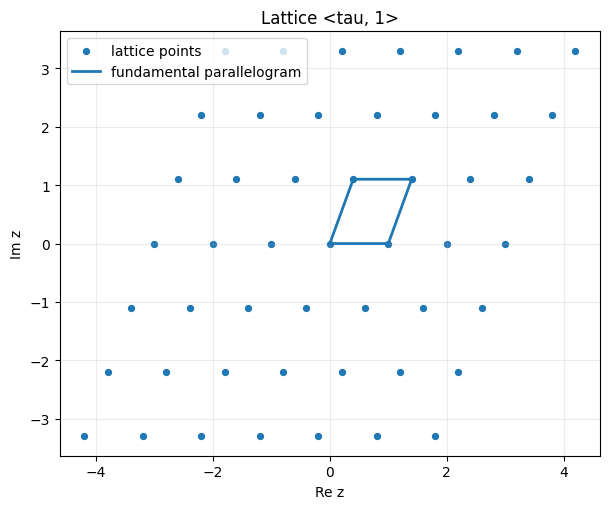

<IPython.core.display.Math object>

行列としては S²=-I。上半平面への作用では -I が自明なので、作用の2乗は恒等。


In [24]:
lab.plot_lattice(.4+1.1j)
plt.show()
S = sp.Matrix([[0, -1], [1, 0]])
T = sp.Matrix([[1, 1], [0, 1]])
assert S**2 == -sp.eye(2) and (S*T)**3 == -sp.eye(2)
display(Math("S^2=" + sp.latex(S**2)))
print("行列としては S²=-I。上半平面への作用では -I が自明なので、作用の2乗は恒等。")

### 4.1 二重周期関数から三次方程式を作る

格子上の周期性を持つ代表的な関数がWeierstrassの$\wp$関数である。

$$\wp(z;\Lambda)=\frac1{z^2}+\sum_{\omega\in\Lambda\setminus\{0\}}
\left(\frac1{(z-\omega)^2}-\frac1{\omega^2}\right).$$

引き算の項は収束を改善するためにある。格子点に二重の極を持ち、それ以外で正則である。また$\wp(z+\omega)=\wp(z)$で、商$\mathbb C/\Lambda$上の関数として扱える。

$$G_{2k}(\Lambda)=\sum_{\omega\ne0}\omega^{-2k}\qquad(k\ge2)$$

というEisenstein級数を使うと、$z=0$の周りでは

$$\wp(z)=z^{-2}+3G_4z^2+5G_6z^4+\cdots.$$

この展開から主要部を比較すると、$\wp'^2-4\wp^3+60G_4\wp+140G_6$の極の項が消える。この差は格子周期を持つ正則関数で、基本領域のコンパクト性から定数となり、定数項も0なので

$$\left(\frac{\wp'(z)}2\right)^2
=\wp(z)^3-15G_4\wp(z)-35G_6$$

が従う。したがって$x=\wp(z),y=\wp'(z)/2$が楕円曲線の点になる。

**一意化定理**は、格子の商から得るこの写像が、原点を含めて複素解析的な群同型であり、逆にすべての複素楕円曲線が格子から得られることを保証する。格子の足し算と三次曲線の群演算が一致することが、両者をつなぐ内容である。[ELLIPTIC](https://dlmf.nist.gov/23.3)

数値実験では$|m|,|n|\le R$の格子和で打ち切り、$R=4,8,16,32,64$と増やす。有限和は厳密な二重周期関数ではないので、微分方程式と周期性の残差を表示する。$G_4,G_6$は別のFourier級数の経路から参照値を作り、同じ打切りを二度使うだけの検証を避ける。

,radius,微分方程式の相対残差,周期1の相対残差,G4の格子和誤差
0,4,0.0015466825,0.0046964347,0.0133722355
1,8,0.0004335692,0.0013248223,0.0037446299
2,16,0.0001150650,0.0003522076,0.0009934943
3,32,0.0000296584,0.0000908248,0.0002560565
4,64,0.0000075300,0.0000230624,0.0000650092


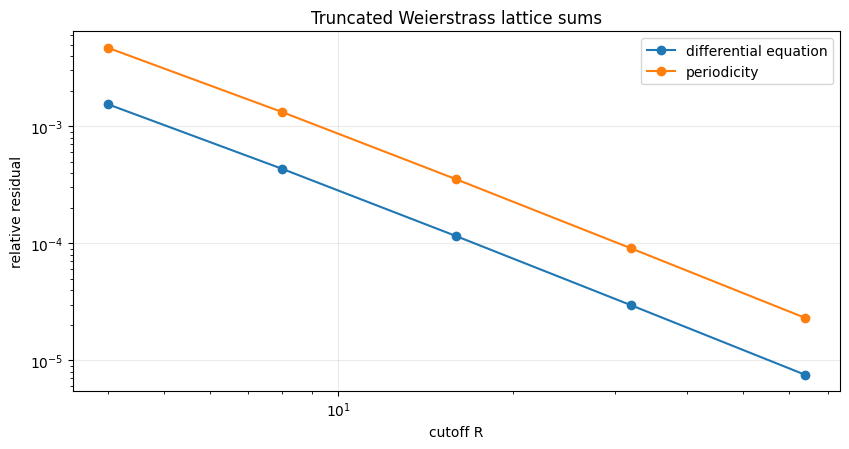

In [25]:
tau_lattice = .3 + 1.1j
z_lattice = .23 + .17j
G4_ref = complex(2*mp.zeta(4)*lab.q_eval(lab.eisenstein_coefficients(4, 60), tau_lattice))
G6_ref = complex(2*mp.zeta(6)*lab.q_eval(lab.eisenstein_coefficients(6, 60), tau_lattice))
wp_rows = []
for radius in (4, 8, 16, 32, 64):
    wp, derivative = lab.weierstrass_wp(z_lattice, tau_lattice, radius)
    wp_shift, _ = lab.weierstrass_wp(z_lattice+1, tau_lattice, radius)
    residual = (derivative/2)**2 - (wp**3-15*G4_ref*wp-35*G6_ref)
    wp_rows.append({"radius": radius, "微分方程式の相対残差": abs(residual)/(1+abs(wp)**3),
                    "周期1の相対残差": abs(wp_shift-wp)/(1+abs(wp)),
                    "G4の格子和誤差": abs(lab.lattice_eisenstein(4, tau_lattice, radius)-G4_ref)})
wp_table = pd.DataFrame(wp_rows)
display(wp_table)
lab.plot_lines(wp_table["radius"], {"differential equation": wp_table["微分方程式の相対残差"],
               "periodicity": wp_table["周期1の相対残差"]},
               "Truncated Weierstrass lattice sums", "cutoff R", "relative residual", logx=True, logy=True, markers=True)
plt.show()

### 4.2 正方格子の尺度を二通りで求める

$\Lambda=\lambda\langle i,1\rangle$とすると

$$G_{2k}(\lambda\Lambda_0)=\lambda^{-2k}G_{2k}(\Lambda_0).$$

正方格子では$G_6(i)=0$なので、対応する曲線を$y^2=x^3-x$にするには

$$\lambda=(15G_4(i))^{1/4}$$

を選べばよい。実数の正の4乗根を取る。

別の経路として、$y^2=x^3-x$の不変微分$dx/(2y)$を実成分に沿って積分すると、その正の実周期は

$$\lambda=\int_1^\infty\frac{dx}{\sqrt{x^3-x}}
=\frac12B\left(\frac14,\frac12\right)
\approx2.6220575542921198.$$

最後の等式は$u=1/x^2$という置換で得られる。ここで$B(a,b)=\int_0^1u^{a-1}(1-u)^{b-1}du$はBeta関数である。格子和に由来するFourier評価と、実周期の積分に由来するBeta関数の値を比較する。実点全体は二つの成分を持つため、後でBSDに使う絶対値付き微分の全実積分は、この周期の2倍になる。

In [26]:
G4_i = 2*mp.zeta(4)*lab.q_eval(lab.eisenstein_coefficients(4, 80), mp.j, dps=60)
square_period = mp.re(15*G4_i)**mp.mpf("0.25")
period_beta = mp.beta(mp.mpf(1)/4, mp.mpf(1)/2)/2
assert abs(square_period-period_beta) < mp.mpf("1e-50")
display(pd.DataFrame({"計算経路": ["Eisenstein級数からの格子尺度", "実積分のBeta関数表示"],
                      "実周期 lambda": [mp.nstr(square_period, 35), mp.nstr(period_beta, 35)]}))
print("2経路の差:", mp.nstr(abs(square_period-period_beta), 8))
print("スケールした曲線の x 係数:", mp.nstr(-15*G4_i/square_period**4, 20))

,計算経路,実周期 lambda
0,Eisenstein級数からの格子尺度,2.6220575542921198104648395898911194
1,実積分のBeta関数表示,2.6220575542921198104648395898911194


2経路の差: 0.0
スケールした曲線の x 係数: (-1.0 + 0.0j)


### 4.3 基本領域へ移動した証拠を行列で残す

$\operatorname{SL}_2(\mathbb Z)$の作用に対する標準的な基本領域は

$$\mathcal F=\{\tau\in\mathbb H:|\operatorname{Re}\tau|\le1/2,\ |\tau|\ge1\}$$

の境界の重複を適切に除いたものになる。境界上の左右の辺や円弧の一部は互いに同一視するので、閉じた図のすべての境界点が別の代表なのではない。

実装では$T$の整数乗で実部を中心へ移し、$|\tau|<1$なら$S$で反転し、繰り返す。

$$\operatorname{Im}\frac{a\tau+b}{c\tau+d}
=\frac{\operatorname{Im}\tau}{|c\tau+d|^2}>0$$

なので上半平面からは出ない。$|\tau|<1$の反転では虚部が増える。

終点だけでなく、整数行列$M$と経路を返す。これにより$\tau_{\rm final}=M\tau_{\rm initial}$と$\det M=1$を確認できる。図は$2.7+0.3i$を基本領域へ移した経路を示す。境界付近の判定は浮動小数点の許容誤差を使い、厳密な同値判定APIではない。

最終点: (-0.33333333333333326+1.6666666666666676j)


<IPython.core.display.Math object>

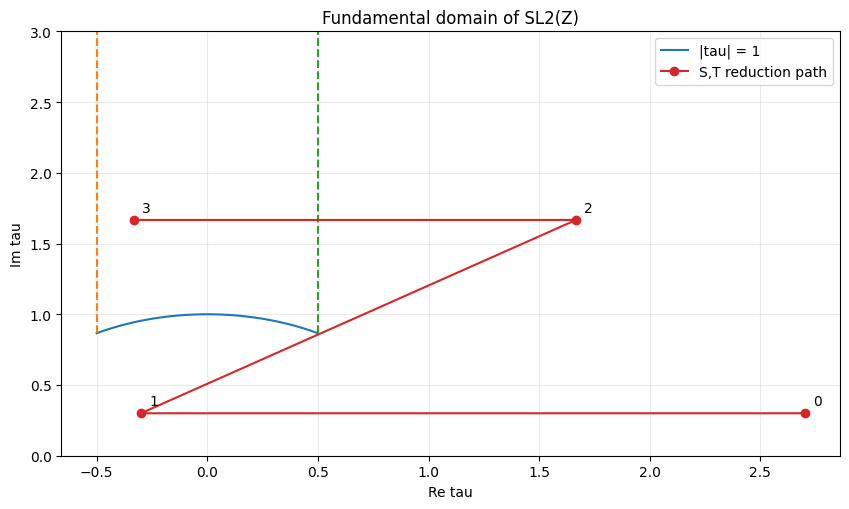

In [27]:
initial_tau = 2.7 + .3j
reduced_tau, reduction_matrix, reduction_path = lab.reduce_to_fundamental(initial_tau)
assert abs(lab.mobius(reduction_matrix, initial_tau)-reduced_tau) < 1e-12
print("最終点:", reduced_tau)
display(Math("M=" + sp.latex(sp.Matrix(2, 2, reduction_matrix))))
lab.plot_fundamental(reduction_path)
plt.show()

### 4.4 合同部分群、cusp、保型曲線

正整数$N$について

$$\begin{aligned}
\Gamma_0(N)&=\left\{\begin{pmatrix}a&b\\c&d\end{pmatrix}\in\operatorname{SL}_2(\mathbb Z):c\equiv0\pmod N\right\},\\
\Gamma_1(N)&=\{\gamma\in\Gamma_0(N):a\equiv d\equiv1\pmod N\},\\
\Gamma(N)&=\{\gamma\in\Gamma_1(N):b\equiv0\pmod N\}.
\end{aligned}$$

$\Gamma(N)\subseteq\Gamma_1(N)\subseteq\Gamma_0(N)$である。上半平面へ$\mathbb Q\cup\{\infty\}$を加えた$\mathbb H^*$の商

$$X_0(N)=\Gamma_0(N)\backslash\mathbb H^*$$

を保型曲線という。境界の有理数・無限遠点の軌道が**cusp**であり、商をコンパクトにするために加える点である。$N=1$ではすべて一つのcuspになるが、素数レベルでは0と$\infty$の二つが残る。

$cusp$を除く$X_0(N)$の点は「複素楕円曲線$E$と、位数$N$の巡回部分群$C\subset E$の組」を同型を除いて分類する。$X_1(N)$では部分群ではなく位数$N$の点を指定する。$X_0(N)$自体が楕円曲線になるとは限らない。

計算には次の種数公式を使う。[DIMS](https://doc.sagemath.org/html/en/reference/modfrm/sage/modular/dims.html)

$$\begin{aligned}
\mu&=N\prod_{p\mid N}(1+1/p),\\
c&=\sum_{d\mid N}\varphi(\gcd(d,N/d)),\\
g(X_0(N))&=1+\frac\mu{12}-\frac{e_2}{4}-\frac{e_3}{3}-\frac c2.
\end{aligned}$$

$\varphi(m)$は$m$以下で$m$と互いに素な正整数の個数。$e_2,e_3$はそれぞれmod $N$の$x^2+1=0$、$x^2+x+1=0$の根の個数である。$N=11$では$(\mu,c,e_2,e_3)=(12,2,0,0)$だから種数1、$N=37$では$(38,2,2,2)$だから種数2となる。

重さ2のcusp形式の空間の次元は、この種数に等しい。これは後述の$f(\tau)d\tau$が保型曲線上の正則微分に対応するためである。種数2の$X_0(37)$から楕円曲線への写像が存在することと、$X_0(37)$自身が楕円曲線であることは別である。

In [28]:
genus_table = pd.DataFrame([lab.gamma0_invariants(N) for N in (1, 2, 3, 4, 5, 7, 11, 13, 14, 17, 22, 23, 26, 32, 37, 49, 50)])
display(genus_table)
assert lab.gamma0_invariants(11)["genus"] == 1
assert lab.gamma0_invariants(37)["genus"] == 2
for p in sp.primerange(5, 80):
    formula = (int(p)+1)//12 - (1 if p % 12 == 1 else 0)
    assert lab.gamma0_invariants(int(p))["genus"] == formula

,N,index,cusps,e2,e3,genus
0,1,1,1,1,1,0
1,2,3,2,1,0,0
2,3,4,2,0,1,0
3,4,6,3,0,0,0
4,5,6,2,2,0,0
5,7,8,2,0,2,0
6,11,12,2,0,0,1
7,13,14,2,2,2,0
8,14,24,4,0,0,1
9,17,18,2,2,0,1


## 5. 保型形式を、変換則とq展開から定義する

整数$k$に対し、$f:\mathbb H\to\mathbb C$が重さ$k$の保型形式であるとは、上半平面で正則で、

$$f\left(\frac{a\tau+b}{c\tau+d}\right)=(c\tau+d)^k f(\tau)$$

を指定した群のすべての行列について満たし、さらにすべてのcuspで正則なことをいう。「正則」は複素微分可能で極を持たないことを意味する。重さは座標変換に伴う倍率を指定する整数である。

$\Gamma_0(N)$には$T$が含まれるので$f(\tau+1)=f(\tau)$となり、$q=e^{2\pi i\tau}$による

$$f(\tau)=\sum_{n\ge0}a_nq^n$$

という展開を持つ。$\infty$のcuspで正則なら負の次数を持たず、そこにおいて0なら定数項が0になる。ほかのcuspも無限遠へ移して同様に調べる必要があり、そこでの周期が$h$なら局所変数は$e^{2\pi i\tau/h}$になる。

**cusp形式**はすべてのcuspで0になる保型形式である。保型形式全体を$M_k(\Gamma)$、cusp形式を$S_k(\Gamma)$と書く。同じ重さの和と定数倍は同じ空間に属し、積では重さが加わる。[MODFORMS](https://wstein.org/books/modform/modform/)

レベル1の基本例は、偶数$k\ge4$に対する正規化Eisenstein級数

$$E_k(\tau)=1-\frac{2k}{B_k}\sum_{n\ge1}\sigma_{k-1}(n)q^n,
\qquad\sigma_r(n)=\sum_{d\mid n}d^r.$$

Bernoulli数$B_k$は$t/(e^t-1)=\sum_{k\ge0}B_kt^k/k!$で定義する。$B_4=-1/30,B_6=1/42$から

$$E_4=1+240\sum\sigma_3(n)q^n,\qquad
E_6=1-504\sum\sigma_5(n)q^n$$

となる。格子和との関係は$G_k(\tau)=2\zeta(k)E_k(\tau)$である。$E_2$は同じ意味のレベル1保型形式ではないので、このAPIには渡さない。

レベル1では偶数$k\ge0$について$\dim M_k=\lfloor k/12\rfloor+1$だが、$k\equiv2\pmod{12}$では1を引く。奇数重さと負の重さでは0になる。これは$M_* =\mathbb C[E_4,E_6]$という構造とも整合する。例えば重さ10は1次元で、$E_{10}$と$E_4E_6$は定数項1の同じ形式だから等しい。次のセルでは次元公式、単項式$E_4^aE_6^b$の重さ$4a+6b$、係数の一致を確認する。[DIMS](https://doc.sagemath.org/html/en/reference/modfrm/sage/modular/dims.html)

In [29]:
M_mod = 400
E4q = lab.eisenstein_coefficients(4, M_mod)
E6q = lab.eisenstein_coefficients(6, M_mod)
E10q = lab.eisenstein_coefficients(10, M_mod)
assert lab.series_mul(E4q, E6q, M_mod) == E10q
print("E4:", lab.qseries_text(E4q, 5))
print("E6:", lab.qseries_text(E6q, 5))
print("E4 E6 = E10 を次数400まで厳密確認。")
display(pd.DataFrame([{"weight": k, "dim M_k": lab.dimension_level1(k),
                      "dim S_k": lab.dimension_level1(k-12),
                      "4a+6b=k の単項式数": sum(4*a+6*b == k for a in range(k//4+1) for b in range(k//6+1))}
                     for k in range(0, 37, 2)]))

E4: 30240*q**5 + 17520*q**4 + 6720*q**3 + 2160*q**2 + 240*q + 1 + O(q^6)
E6: -1575504*q**5 - 532728*q**4 - 122976*q**3 - 16632*q**2 - 504*q + 1 + O(q^6)
E4 E6 = E10 を次数400まで厳密確認。


,weight,dim M_k,dim S_k,4a+6b=k の単項式数
0,0,1,0,1
1,2,0,0,0
2,4,1,0,1
3,6,1,0,1
4,8,1,0,1
5,10,1,0,1
6,12,2,1,2
7,14,1,0,1
8,16,2,1,2
9,18,2,1,2


### 5.1 判別式形式Δと691の合同式

正規化判別式形式を

$$\Delta_q=q\prod_{m\ge1}(1-q^m)^{24}=\sum_{n\ge1}\tau(n)q^n$$

と書く。$\tau(n)$はRamanujanのtau関数であり、上半平面の変数$\tau$とは別の記号である。

$E_4^3-E_6^2$は重さ12で、定数項が$1-1=0$だからcusp形式である。$\dim S_{12}=1$で$\Delta_q$がその基底なので、両者は定数倍になる。$q^1$の係数を比べると$3\cdot240-2(-504)=1728$であり、

$$E_4^3-E_6^2=1728\Delta_q$$

を得る。以下のコードはこの恒等式の400次までを、整数・有理数で確認する。無限積側も、直接積と第5.4節の再帰という二つの方式で展開する。

691が現れる理由も係数から見える。$B_{12}=-691/2730$より

$$E_{12}=1+\frac{65520}{691}\sum_{n\ge1}\sigma_{11}(n)q^n.$$

重さ12の次元と定数項・$q$の係数から

$$691E_{12}=441E_4^3+250E_6^2
=691E_6^2+762048\Delta_q.$$

$n\ge1$の係数を取りmod 691で見ると、$762048\equiv65520\not\equiv0$だから

$$\tau(n)\equiv\sigma_{11}(n)\pmod{691}$$

が従う。これは次元・正則性などの定理を使った導出である。コードが400個を検査しただけで全$n$に外挿しているのではない。

In [30]:
Deltaq = lab.eta_product_coefficients({1: 24}, M_mod)
E4cube = lab.series_power(E4q, 3, M_mod)
E6square = lab.series_power(E6q, 2, M_mod)
assert [(a-b)/1728 for a, b in zip(E4cube, E6square)] == Deltaq
assert Deltaq[:101] == lab.eta_product_direct({1: 24}, 100)
sigma11 = lab.divisor_sums(M_mod, 11)
assert all((Deltaq[n]-sigma11[n]) % 691 == 0 for n in range(1, M_mod+1))
display(pd.DataFrame([{"n": n, "tau(n)": Deltaq[n], "sigma11(n) mod 691": sigma11[n] % 691,
                      "tau(n) mod 691": Deltaq[n] % 691} for n in range(1, 17)]))
print("Ramanujanの691合同式も次数400まで厳密一致。全nに対する導出は第5.1節の係数比較。")

,n,tau(n),sigma11(n) mod 691,tau(n) mod 691
0,1,1,1,1
1,2,-24,667,667
2,3,252,252,252
3,4,-1472,601,601
4,5,4830,684,684
5,6,-6048,171,171
6,7,-16744,531,531
7,8,84480,178,178
8,9,-113643,372,372
9,10,-115920,168,168


Ramanujanの691合同式も次数400まで厳密一致。全nに対する導出は第5.1節の係数比較。


### 5.2 j不変量は、形式的除算でも数値評価でも調べられる

$$j(\tau)=\frac{E_4(\tau)^3}{\Delta_q(\tau)}
=q^{-1}+744+196884q+21493760q^2+\cdots.$$

分子も分母も重さ12なので、比の重さは0になり、$j(\gamma\tau)=j(\tau)$を満たす。ただしcuspで$q^{-1}$の極を持つため、正則な保型形式ではなく**保型関数**である。

格子から作る曲線$y^2=x^3-15G_4x-35G_6$の$j=c_4^3/\Delta_E$とも一致する。$\Delta_E=(2\pi)^{12}\Delta_q$という尺度の違いがあるので、曲線の判別式と正規化した形式を同じ数だと思ってはいけない。

正方格子では$j(i)=1728$、六角格子では$j((-1+\sqrt3i)/2)=0$になる。形式的除算で最初の係数を作り、これらの値を多倍長計算で検査する。非常に小さい非零の数値が出る場合でも、表示値を黙って0へ置き換えない。

In [31]:
q_times_j = lab.series_div(E4cube[:9], Deltaq[1:10], 8)
assert q_times_j[:4] == [1, 744, 196884, 21493760]
display(pd.DataFrame({"qの指数": range(-1, 8), "jの係数": [str(x) for x in q_times_j]}))
tau_i = mp.j
tau_rho = (-1+mp.sqrt(3)*mp.j)/2
j_i = lab.q_eval(E4q, tau_i)**3/lab.q_eval(Deltaq, tau_i)
j_rho = lab.q_eval(E4q, tau_rho)**3/lab.q_eval(Deltaq, tau_rho)
assert abs(j_i-1728) < mp.mpf("1e-45") and abs(j_rho) < mp.mpf("1e-45")
print("j(i) =", mp.nstr(j_i, 35))
print("j((-1+sqrt(3)i)/2) の絶対値 =", mp.nstr(abs(j_rho), 5))

,qの指数,jの係数
0,-1,1
1,0,744
2,1,196884
3,2,21493760
4,3,864299970
5,4,20245856256
6,5,333202640600
7,6,4252023300096
8,7,44656994071935


j(i) = (1728.0 + 0.0j)
j((-1+sqrt(3)i)/2) の絶対値 = 3.3374e-149


### 5.3 変換則の数値的な確認

$S,T$はレベル1の群を生成するので、$E_k$について

$$E_k(\tau+1)=E_k(\tau),\qquad E_k(-1/\tau)=\tau^kE_k(\tau)$$

を確認する。次のセルは$E_4,E_6,\Delta_q,j$の残差を多倍長で計算する。$j$の重さは0として扱う。

残差は$|\text{左辺}-\text{右辺}|$や、値の大きさで割った相対残差である。有限次数の展開と有限精度の関数評価なので、すべての$\tau$に対する恒等式を数値検査だけで証明するものではない。特に虚部が小さいと$|q|$が1に近づき、同じ項数でも精度が悪化する。

In [32]:
modular_rows = []
for weight, coeff in [(4, E4q), (6, E6q), (12, Deltaq)]:
    tau = mp.mpc("0.27", "0.89")
    f_tau = lab.q_eval(coeff, tau)
    err_T = abs(lab.q_eval(coeff, tau+1)-f_tau)/(1+abs(f_tau))
    err_S = abs(lab.q_eval(coeff, -1/tau)-tau**weight*f_tau)/(1+abs(tau**weight*f_tau))
    modular_rows.append({"weight": weight, "T変換相対残差": mp.nstr(err_T, 6), "S変換相対残差": mp.nstr(err_S, 6)})
    assert err_T < mp.mpf("1e-45") and err_S < mp.mpf("1e-45")
display(pd.DataFrame(modular_rows))

,weight,T変換相対残差,S変換相対残差
0,4,2.39761e-51,2.99339e-51
1,6,4.34049e-51,5.87322e-51
2,12,2.98258e-53,2.51861e-53


### 5.4 楕円曲線とη積を、独立に計算して比較する

Dedekindのη関数を

$$\eta(\tau)=q^{1/24}\prod_{m\ge1}(1-q^m)$$

と定義する。導手11の楕円曲線に対応する形式は

$$f_{11}(\tau)=\eta(\tau)^2\eta(11\tau)^2
=q\prod_{m\ge1}(1-q^m)^2(1-q^{11m})^2.$$

この具体的なη積は重さ2、レベル11のcusp形式である。[ETA11](https://aimath.org/~aimath/WWN/rmtapplications/articles/html/8a/) η積の保型性判定定理をこの場合に適用すると、重さは$(2+2)/2=2$、二つの合同条件の和は$1\cdot2+11\cdot2=24$と$11\cdot2+1\cdot2=24$、指標は$11^2$が平方なので自明、二つのcuspでの消失次数はともに1となる。任意の無限積が保型形式になるわけではない。

η積の係数は点数を使わず生成する。一般に

$$P(q)=\prod_{m\ge1}(1-q^m)^{r_m}=\sum_{n\ge0}c_nq^n,\qquad c_0=1$$

なら、対数微分より

$$q\frac{P'}P=-\sum_{n\ge1}\left(\sum_{d\mid n}r_dd\right)q^n=:\sum_{n\ge1}b_nq^n.$$

両辺に$P$を掛けて係数を比べると

$$n c_n=\sum_{j=1}^n b_jc_{n-j}.$$

これで既知の低次係数から次を決められる。`eta_product_coefficients({1:2,11:2},400)`はη関数の引数の倍率を辞書のキー、指数を値として受け取る。先頭の$q$も含めて返す。整数になるはずの割り算で余りが出たら停止する。

独立した二経路

$$\#E(\mathbb F_p)\longrightarrow a_p\longrightarrow a_n,
\qquad\eta\text{積}\longrightarrow c_n$$

を比較すると、1次から400次まで一致する。$a_n$の素数冪での再帰は第6節で導く。先頭は

$$f_{11}=q-2q^2-q^3+2q^4+q^5+2q^6-2q^7-2q^9-2q^{10}+q^{11}+\cdots.$$

$q^8$の係数は0である。この比較は有限計算として厳密だが、それ単独で一般の保型性定理を証明したことにはならない。

In [33]:
f11_eta = lab.eta_product_coefficients({1: 2, 11: 2}, M_mod)
f11_ec = lab.l_coefficients(lab.CURVES["11a1"], M_mod)
assert f11_eta == list(f11_ec)
assert f11_eta == lab.eta_product_direct({1: 2, 11: 2}, M_mod)
display(pd.DataFrame([{"n": n, "eta積": f11_eta[n], "楕円曲線から": f11_ec[n], "差": f11_eta[n]-f11_ec[n]}
                      for n in range(1, 25)]))
print("相互に独立な構成によって、1 <= n <= 400 の全係数が厳密一致。")

,n,eta積,楕円曲線から,差
0,1,1,1,0
1,2,-2,-2,0
2,3,-1,-1,0
3,4,2,2,0
4,5,1,1,0
5,6,2,2,0
6,7,-2,-2,0
7,8,0,0,0
8,9,-2,-2,0
9,10,-2,-2,0


相互に独立な構成によって、1 <= n <= 400 の全係数が厳密一致。


#### Sturm境界を使える前提

同じ重さ$k$、レベル$N$、指標の保型形式であると既に分かっている二つの形式は、Sturm境界

$$B=\left\lfloor\frac{k}{12}[\operatorname{SL}_2(\mathbb Z):\Gamma_0(N)]\right\rfloor$$

まで係数が一致すれば、適切な係数体のもとで等しいと判定できる。レベル11、重さ2では$B=2$になる。[DIMS](https://doc.sagemath.org/html/en/reference/modfrm/sage/modular/dims.html)

「楕円曲線から整数列を作った」だけでは、その級数が保型形式空間に属することはまだ示していない。Sturm境界はその所属まで自動的に証明する定理ではない。この前提を省略すると、最初の二係数だけを合わせた任意の級数も保型形式だとする誤った議論になる。

#### Hecke作用素を係数配列へ作用させる

$$V_pf(\tau)=f(p\tau),\qquad
U_pf(\tau)=\frac1p\sum_{j=0}^{p-1}f\left(\frac{\tau+j}p\right)$$

と置く。$p$乗根の和を使えば、$U_p$は$q^{pn}$の係数を$q^n$へ移し、$V_p$は$q^n$を$q^{pn}$へ移す。指標$\chi$の重さ$k$では

$$T_p=U_p+\chi(p)p^{k-1}V_p,$$
$$[q^n]T_pf=a_{pn}+\chi(p)p^{k-1}a_{n/p}.$$

$p\nmid n$なら$a_{n/p}=0$。自明指標でも$p\mid N$では$\chi(p)=0$として$T_p=U_p$を使う。固有形式とは、すべてのHecke作用素について固有ベクトルになる形式である。$a_1=1$と正規化すると$q$係数を比較して固有値が$a_p$と分かる。

例えば出力24次までに$T_{11}$を作用させるなら、入力は264次まで必要である。不足分を0埋めするのではなく、実装では例外にする。レベル11の形式について$p=2,3,5,7,11$で$T_pf=a_pf$を検査する。

素数以外の作用素は、$T_1=\mathrm{Id}$、互いに素な$m,n$では$T_{mn}=T_mT_n$、$p\nmid N$では

$$T_{p^{r+1}}=T_pT_{p^r}-\chi(p)p^{k-1}T_{p^{r-1}},$$

$p\mid N$では$T_{p^r}=U_p^r$として定められる。これが「すべてのHecke作用素」の意味である。

指標の由来も述べておく。$\Gamma_1(N)$の形式に対し、$d\equiv\delta\pmod N$となる$\gamma=\begin{pmatrix}a&b\\c&d\end{pmatrix}\in\Gamma_0(N)$を選び、

$$(\langle\delta\rangle f)(\tau)=(c\tau+d)^{-k}f(\gamma\tau)$$

と定めたものをdiamond作用素という。$\delta$はmod $N$の単元、すなわち$\gcd(\delta,N)=1$であることが必要。行列の選び方を変えた差は$\Gamma_1(N)$の作用になるため、形式上の作用は変わらない。これらの共通固有空間で$\langle\delta\rangle f=\chi(\delta)f$となるとき、その$\chi$が上の式の指標になる。この実験の楕円曲線に対応する形式では自明指標だけを使う。


In [34]:
print("レベル11・重さ2のSturm境界:", lab.sturm_bound(11, 2))
hecke_rows = []
for p in (2, 3, 5, 7, 11):
    image = lab.hecke_prime(f11_eta, p, 2, 11, out_degree=24)
    assert image == [f11_eta[p]*c for c in f11_eta[:25]]
    hecke_rows.append({"p": p, "固有値 a_p": f11_eta[p], "検証した出力次数": 24,
                       "演算子": "U_p" if p == 11 else "U_p+p V_p"})
display(pd.DataFrame(hecke_rows))
assert lab.hecke_prime(Deltaq, 2, 12, 1, 24) == [Deltaq[2]*c for c in Deltaq[:25]]
print("Deltaでは T2 = U2 + 2^11 V2、固有値 tau(2)=-24。")

レベル11・重さ2のSturm境界: 2


,p,固有値 a_p,検証した出力次数,演算子
0,2,-2,24,U_p+p V_p
1,3,-1,24,U_p+p V_p
2,5,1,24,U_p+p V_p
3,7,-2,24,U_p+p V_p
4,11,1,24,U_p


Deltaでは T2 = U2 + 2^11 V2、固有値 tau(2)=-24。


### 5.5 二次元空間でHecke作用素を対角化する

$S_2(\Gamma_0(37))$は種数公式から2次元である。計算例の基底として、次の二形式を指定する。

$$\begin{aligned}
f&=q+q^3-2q^4-q^7-2q^9+3q^{11}-2q^{12}-4q^{13}+O(q^{16}),\\
g&=q^2+2q^3-2q^4+q^5-3q^6-4q^9-2q^{10}+4q^{11}+O(q^{12}).
\end{aligned}$$

ここでは「この二つがこの空間の基底である」という保型形式のデータを入力として使う。任意の二つの有限多項式を保型形式と判定する機能ではない。全空間の基底構成には、例えばmodular symbolsなど別のアルゴリズムが必要になる。[MODFORMS](https://wstein.org/books/modform/modform/)

$q$と$q^2$の係数がそれぞれ$(1,0),(0,1)$なので、空間の任意の元の最初の二係数が、そのままこの基底での座標になる。Hecke作用素が空間を保つという定理を使い、$T_2,T_3$の最初の二係数を計算すれば

$$[T_2]_{f,g}=\begin{pmatrix}0&1\\0&-2\end{pmatrix},\qquad
[T_3]_{f,g}=\begin{pmatrix}1&2\\0&-3\end{pmatrix}.$$

列は各基底ベクトルの像である。二行列は可換で、共通固有ベクトルは$(1,0)$と$(1,-2)$、すなわち$f$と$f-2g$になる。二曲線

$$E_A:y^2+y=x^3-x,\qquad E_B:y^2+y=x^3+x^2-23x-50$$

の点数から得た係数を比べると、$E_A$が$f-2g$、$E_B$が$f$に対応する。単に「二つの曲線に二つの基底がある」ではなく、**同時固有形式へ基底を取り直すこと**が重要である。

In [35]:
f37 = [0]*16
for n, value in {1: 1, 3: 1, 4: -2, 7: -1, 9: -2, 11: 3, 12: -2, 13: -4}.items():
    f37[n] = value
g37 = [0]*12
for n, value in {2: 1, 3: 2, 4: -2, 5: 1, 6: -3, 9: -4, 10: -2, 11: 4}.items():
    g37[n] = value
T2_matrix = sp.Matrix.hstack(*[sp.Matrix(lab.hecke_prime(v, 2, 2, 37, 2)[1:3]) for v in (f37, g37)])
T3_matrix = sp.Matrix.hstack(*[sp.Matrix(lab.hecke_prime(v, 3, 2, 37, 2)[1:3]) for v in (f37, g37)])
assert T2_matrix == sp.Matrix([[0, 1], [0, -2]])
assert T3_matrix == sp.Matrix([[1, 2], [0, -3]])
assert T2_matrix*T3_matrix == T3_matrix*T2_matrix
display(Math("T_2="+sp.latex(T2_matrix)+r",\qquad T_3="+sp.latex(T3_matrix)))
display(T2_matrix.eigenvects())
a37A = lab.l_coefficients(lab.CURVES["37a1"], 15)
a37B = lab.l_coefficients(lab.CURVES["37b1"], 15)
assert list(a37B) == f37
assert list(a37A[:12]) == [f37[n]-2*g37[n] for n in range(12)]
display(pd.DataFrame([{"n": n, "基底f": f37[n], "基底g": g37[n],
                      "f-2g": f37[n]-2*g37[n], "曲線37a1から": a37A[n]}
                     for n in range(1, 12)]))

<IPython.core.display.Math object>

[(-2,
  1,
  [Matrix([
   [-1/2],
   [   1]])]),
 (0,
  1,
  [Matrix([
   [1],
   [0]])])]

,n,基底f,基底g,f-2g,曲線37a1から
0,1,1,0,1,1
1,2,0,1,-2,-2
2,3,1,2,-3,-3
3,4,-2,-2,2,2
4,5,0,1,-2,-2
5,6,0,-3,6,6
6,7,-1,0,-1,-1
7,8,0,0,0,0
8,9,-2,-4,6,6
9,10,0,-2,4,4


### 5.6 old form・newformとPetersson積

低いレベル$M$のcusp形式$h(\tau)$から、$M\mid N$かつ$d\mid N/M$に対して$h(d\tau)$を作ると、レベル$N$の形式として扱える。これらが張る部分をold spaceと呼ぶ。例えばレベル22では、レベル11の$f_{11}(\tau)$と$f_{11}(2\tau)$が独立な二方向を作る。

cusp形式同士にはPetersson積

$$\langle f,g\rangle_\Gamma
=\int_{\Gamma\backslash\mathbb H}f(\tau)\overline{g(\tau)}
 y^k\frac{dx\,dy}{y^2},\qquad\tau=x+iy$$

を入れられる。複素共役を付けるのでHermite内積になる。双曲面積$dx\,dy/y^2$と重さの倍率が打ち消し合い、代表領域の選び方に依存しない。指数で割る別の正規化もあるが、ここで数値計算するレベル1では指数が1なので差はない。

old spaceの直交補空間がnew spaceで、その中の$a_1=1$に正規化した同時Hecke固有形式をnewformと呼ぶ。Fourier係数の正規化$a_1=1$と内積のノルム1は違う。一般に両方を同時に課すことはできない。

In [36]:
old1 = f11_eta[:31]
old2 = [f11_eta[n//2] if n % 2 == 0 else 0 for n in range(31)]
old_coordinates = sp.Matrix([[old1[1], old2[1]], [old1[2], old2[2]]])
assert old_coordinates.det() != 0
assert lab.gamma0_invariants(22)["genus"] == 2
print("レベル22のold formsの先頭2係数による独立性:")
display(old_coordinates)
norm_rows = [{"求積パラメータ": nodes, "DeltaのPetersson norm^2": lab.petersson_delta(nodes)} for nodes in (24, 36, 48, 72)]
display(pd.DataFrame(norm_rows))

レベル22のold formsの先頭2係数による独立性:


Matrix([
[ 1, 0],
[-2, 1]])

,求積パラメータ,DeltaのPetersson norm^2
0,24,0.0000010354
1,36,0.0000010354
2,48,0.0000010354
3,72,0.0000010354


レベル1の正規化$\Delta_q$に対し、基本領域上の積分は

$$\langle\Delta_q,\Delta_q\rangle
=\int_{-1/2}^{1/2}\int_{\sqrt{1-x^2}}^\infty
|\Delta_q(x+iy)|^2y^{10}\,dy\,dx.$$

重さ12だから$y^{12}/y^2=y^{10}$である。数値セルは$y\le4$、Fourier次数30で打ち切り、Gauss–Legendre求積の節点数を変える。値は約$1.03536\times10^{-6}$に安定し、1ではない。

cusp形式は$y\to\infty$で指数的に減衰するため積分が収束する。ただし、この実装は求積誤差や領域打切りの保証区間を返していない。節点数を増やして値が落ち着くことと、すべての表示桁に数学的保証があることは区別する。

## 6. 有限体の点数をL関数へまとめる

最小モデルに対し、局所多項式を

$$P_p(T)=\begin{cases}
1-a_pT+pT^2&\text{良い還元},\\
1-T&\text{分裂乗法的還元},\\
1+T&\text{非分裂乗法的還元},\\
1&\text{加法的還元}
\end{cases}$$

と定める。悪い素数でも、それぞれ$a_p=1,-1,0$と書く。Hasse–Weil L関数は

$$L(E,s)=\prod_p P_p(p^{-s})^{-1}.$$

各素数が局所的な情報を一つずつ提供し、その積で大域的な関数を作る。$s$は複素数で、$n^{-s}=e^{-s\log n}$とする。

良い素数では

$$\frac1{1-a_pT+pT^2}=\sum_{r\ge0}a_{p^r}T^r$$

と置いて分母を掛け、係数を比較すると

$$a_{p^0}=1,\quad a_{p^1}=a_p,\quad
 a_{p^{r+1}}=a_pa_{p^r}-pa_{p^{r-1}}.$$

悪い素数では$a_{p^r}=a_p^r$である。互いに素な$m,n$では$a_{mn}=a_ma_n$とすれば、素因数分解の一意性から

$$L(E,s)=\sum_{n\ge1}a_nn^{-s}$$

と展開できる。重さ2のHecke固有値の再帰と同じ形になるのが、保型形式との接続の手がかりである。

**導手$N$**は悪い還元を測る整数で、$N=\prod p^{f_p}$と書く。良い還元では$f_p=0$、乗法的では1、加法的で$p\ge5$なら2。2と3の加法的還元では追加項があり、Tateアルゴリズムなどが必要になる。以下で使う5曲線の係数、導手、符号、悪い素数の$a_p$は、すべて表と `CURVES` に明示してある。[ECAPI](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/ell_rational_field.html) [LSERIES](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/lseries_ell.html)

In [37]:
curve_metadata = []
for name, data in lab.CURVES.items():
    for p, a_bad in data.bad_ap:
        # 採用済み最小整モデルでは、特異三次曲線全体の計数とも局所係数が整合する。
        assert p+1-data.curve.count_mod_p(p) == a_bad
    curve_metadata.append({"曲線": name, "係数": str(tuple(int(v) for v in data.curve.ainvs)),
                           "判別式": str(data.curve.invariants()["discriminant"]),
                           "導手": data.conductor, "符号w": data.root_number, "bad a_p": str(data.bad_ap)})
display(pd.DataFrame(curve_metadata))
a11 = lab.l_coefficients(lab.CURVES["11a1"], 1400)
assert a11[4] == a11[2]**2-2
assert a11[8] == a11[2]*a11[4]-2*a11[2] == 0
assert a11[121] == a11[11]**2 == 1
assert a11[6] == a11[2]*a11[3]
print("a2,a4,a8 =", a11[2], a11[4], a11[8], "; a11,a121 =", a11[11], a11[121])

,曲線,係数,判別式,導手,符号w,bad a_p
0,11a1,"(0, -1, 1, -10, -20)",-161051,11,1,"((11, 1),)"
1,37a1,"(0, 0, 1, -1, 0)",37,37,-1,"((37, -1),)"
2,37b1,"(0, 1, 1, -23, -50)",50653,37,1,"((37, 1),)"
3,389a1,"(0, 1, 1, -2, 0)",389,389,1,"((389, 1),)"
4,5077a1,"(0, 0, 1, -7, 6)",5077,5077,-1,"((5077, -1),)"


a2,a4,a8 = -2 2 0 ; a11,a121 = 1 1


### 6.1 保型性定理の主張と、収束する範囲

**保型性定理**は、有理数体上の導手$N$の楕円曲線$E$に対し、重さ2・レベル$N$・自明指標の正規化newform

$$f_E(\tau)=\sum_{n\ge1}a_nq^n\in S_2(\Gamma_0(N))$$

が存在し、$L(E,s)=L(f_E,s)$となることを保証する。逆に、係数が有理数のそのようなnewformは、有理数体上の楕円曲線の**同種類**に対応する。同種とは、群構造を保つ有限核の非定数代数写像で結ばれる関係である。同じL関数が曲線の一つの方程式を一意に決めるわけではない。[MODFORMS](https://wstein.org/books/modform/modform/)

ここでの係数規約では解析的な中心は$s=1$である。変数を$1/2$ずらして中心を$1/2$に置く規約とは混ぜない。

Hasse境界から、良い素数で$1-a_pT+pT^2=(1-\alpha_pT)(1-\beta_pT)$、$|\alpha_p|=|\beta_p|=\sqrt p$と書ける。よって

$$|a_{p^r}|\le(r+1)p^{r/2},\qquad |a_n|\le d(n)\sqrt n,$$

ここで$d(n)$は正の約数の個数である。$\sum d(n)n^{-u}=\zeta(u)^2$は$u>1$で収束するので、L級数は$\operatorname{Re}s>3/2$で絶対収束する。Euler積もこの半平面で扱える。

比較する5曲線はいずれも表にある一つの悪い素数で乗法的還元を持つ。全体の符号$w$は、実無限素点の符号$-1$と乗法的素点の符号$-a_p$の積から、この場合$w=a_p$となる。符号をランクの偶奇から決めたのではない。

なお、$a_{p^2}=a_p^2-p$と、$\#E(\mathbb F_{p^2})$に使う$\alpha_p^2+\beta_p^2=a_p^2-2p$は異なる。前者はL級数の係数、後者は拡大体でのトレースである。

まず$s=2$でDirichlet部分和とEuler部分積を、後述のMellin評価と比べる。打切り方法が異なるので、同じ上限でも二つの部分近似が一致する必要はない。

,cutoff,Dirichlet有限和(s=2),Euler有限積(s=2),Mellin積分参照値
0,10,0.5239367599,0.5304988431,0.5460480362
1,20,0.5527449555,0.5436791335,0.5460480362
2,40,0.5494830568,0.5477388170,0.5460480362
3,80,0.5440503547,0.5450657418,0.5460480362
4,160,0.5469489493,0.5456252128,0.5460480362
5,320,0.5463919307,0.5460723863,0.5460480362
6,640,0.5458523580,0.5460611903,0.5460480362
7,1280,0.5460489697,0.5459730332,0.5460480362


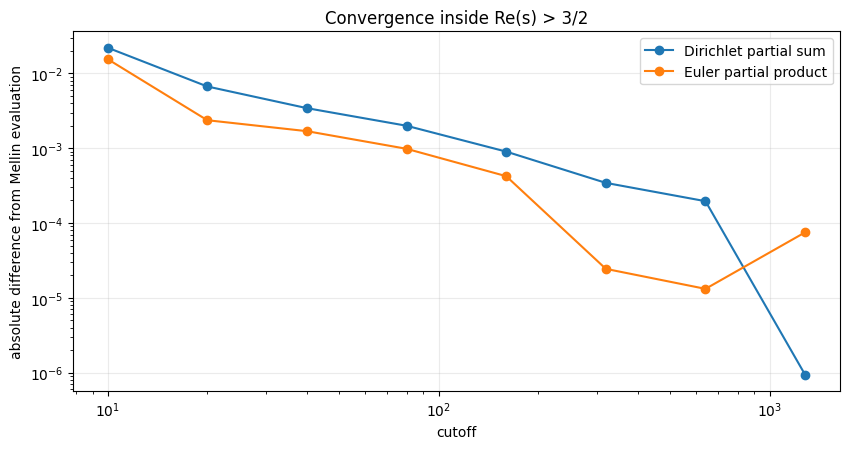

In [38]:
L11_quad = lab.MellinQuadrature(lab.CURVES["11a1"], terms=300, nodes=500)
L11_at2_reference = float(L11_quad.value(2.0))
cutoffs = [10, 20, 40, 80, 160, 320, 640, 1280]
convergence_rows = [{"cutoff": M, "Dirichlet有限和(s=2)": lab.dirichlet_partial(a11[:M+1], 2.0),
                     "Euler有限積(s=2)": lab.euler_partial(lab.CURVES["11a1"], 2.0, M),
                     "Mellin積分参照値": L11_at2_reference} for M in cutoffs]
convergence_table = pd.DataFrame(convergence_rows)
display(convergence_table)
lab.plot_lines(cutoffs, {"Dirichlet partial sum": abs(convergence_table["Dirichlet有限和(s=2)"]-L11_at2_reference),
                         "Euler partial product": abs(convergence_table["Euler有限積(s=2)"]-L11_at2_reference)},
               "Convergence inside Re(s) > 3/2", "cutoff", "absolute difference from Mellin evaluation", logx=True, logy=True, markers=True)
plt.show()

### 6.2 s=1へ、そのまま部分和を代入しない

中心$s=1$は、今の絶対収束の保証範囲に含まれない。

$$\sum_{n=1}^M\frac{a_n}{n}$$

を適当な$M$で止めても、それが$L(E,1)$の制御された近似になるとは限らない。ここで言っているのは「中心の生の級数が必ず発散する」ということではなく、絶対収束の議論と有限打切りだけでは精度の保証にならない、ということである。

次の図では、導手11の曲線の生の部分和と、指数減衰を利用して求めた中心値を比較する。部分和が揺れたり、一時的に近くなったりしても、それだけでは収束速度は分からない。中心付近の解析には、別の表示を用意する。

,M,sum a_n/n,解析接続によるL(1)
0,10,-0.0079365079,0.25384186085591068434
1,20,0.3976210064,0.25384186085591068434
2,40,0.3731876416,0.25384186085591068434
3,80,0.0987499725,0.25384186085591068434
4,160,0.4010781782,0.25384186085591068434
5,320,0.3604996073,0.25384186085591068434
6,640,0.1294669013,0.25384186085591068434
7,1280,0.2548384396,0.25384186085591068434


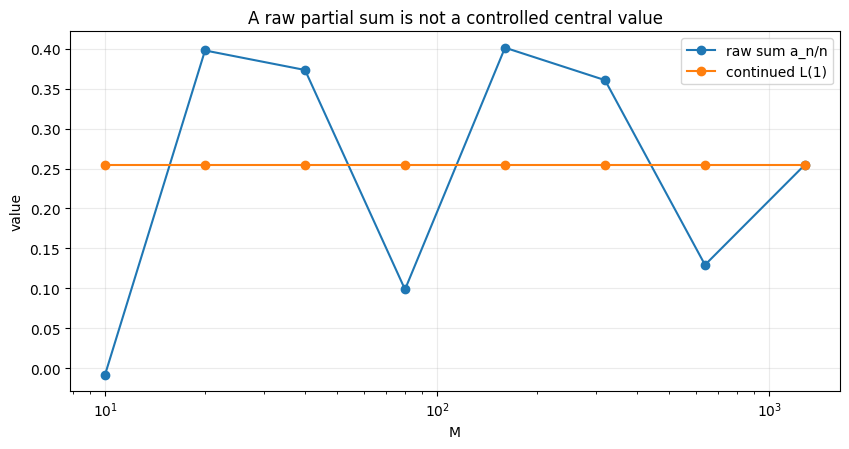

In [39]:
central11 = lab.central_L(lab.CURVES["11a1"], N=160, dps=60)
raw_at1 = [lab.dirichlet_partial(a11[:M+1], 1.0) for M in cutoffs]
display(pd.DataFrame({"M": cutoffs, "sum a_n/n": raw_at1,
                      "解析接続によるL(1)": [mp.nstr(central11["value"], 20)]*len(cutoffs)}))
lab.plot_lines(cutoffs, {"raw sum a_n/n": raw_at1, "continued L(1)": [float(central11["value"])]*len(cutoffs)},
               "A raw partial sum is not a controlled central value", "M", "value", logx=True, markers=True)
plt.show()

### 6.3 Mellin変換から、中心でも使える積分を導く

$cusp$形式$f(\tau)=\sum_{n\ge1}a_ne^{2\pi in\tau}$に対し、最初は和と積分を交換できる範囲で

$$\int_0^\infty f(iy)y^{s-1}dy
=\sum_{n\ge1}a_n\int_0^\infty e^{-2\pi ny}y^{s-1}dy
=(2\pi)^{-s}\Gamma(s)L(f,s)$$

を得る。$u=2\pi ny$という置換を使った。$\Gamma(s)=\int_0^\infty e^{-u}u^{s-1}du$がGamma関数である。

導手$N$、関数等式の符号$w\in\{1,-1\}$を使って

$$c=\frac{2\pi}{\sqrt N},\quad
F(t)=f\left(\frac{it}{\sqrt N}\right)=\sum_{n\ge1}a_ne^{-cnt}$$

と置く。重さ2のFricke変換の固有値関係は

$$f\left(-\frac1{N\tau}\right)=-wN\tau^2f(\tau),\qquad
F(1/t)=wt^2F(t).$$

完備L関数を

$$\Lambda(E,s)=N^{s/2}(2\pi)^{-s}\Gamma(s)L(E,s)$$

と定めると、$\Lambda(E,s)=\int_0^\infty F(t)t^{s-1}dt$。区間を$(0,1)$と$(1,\infty)$に分け、前半で$t=1/u$と置けば

$$\boxed{\Lambda(E,s)=\int_1^\infty F(t)\left(t^{s-1}+wt^{1-s}\right)dt}$$

となる。$F(t)$は指数的に減衰するので、この式はすべての$s$に対し解析的な関数を与え、

$$\Lambda(E,s)=w\Lambda(E,2-s),\qquad
L(E,s)=\frac{c^s}{\Gamma(s)}\Lambda(E,s)$$

が得られる。これが解析接続と関数等式の関係である。任意に作った係数列に対して、右辺が元のDirichlet級数の解析接続になるわけではない。保型性とFricke関係を使っている。

`MellinQuadrature` は$F$を有限項で近似し、$t\in[1,T]$をGauss–Legendre求積する。別経路として、上側不完全Gamma関数

$$\Gamma(s,x)=\int_x^\infty e^{-u}u^{s-1}du$$

を使い、項別に積分した

$$\Lambda(E,s)=\sum_{n\ge1}a_n\left[(cn)^{-s}\Gamma(s,cn)
+w(cn)^{s-2}\Gamma(2-s,cn)\right]$$

も実装する。二つの数値方式を複素点$s=1.2+0.4i$で比較する。結果の差が小さいことは実装の相互確認になるが、係数打切りを共有している点や、両方式が関数等式を使用している点は残る。

In [40]:
complex_checks = []
for label in ("11a1", "37a1", "37b1"):
    data = lab.CURVES[label]
    quad = lab.MellinQuadrature(data, terms=240, nodes=500)
    s_test = mp.mpc("1.2", "0.4")
    gamma_value = lab.completed_gamma_sum(data, s_test, N=140, dps=50)
    quad_value = quad.completed(complex(s_test))
    residual = abs(quad_value-complex(gamma_value))
    assert residual < 2e-10
    complex_checks.append({"曲線": label, "s": str(s_test),
                           "不完全Gamma級数": mp.nstr(gamma_value, 20),
                           "Gauss求積との差": residual})
display(pd.DataFrame(complex_checks))

,曲線,s,不完全Gamma級数,Gauss求積との差
0,11a1,(1.2 + 0.4j),(0.13192961263577864566 + 0.0026963022014438867357j),3.9706363605e-15
1,37a1,(1.2 + 0.4j),(0.054369651794425048304 + 0.11753783963220707788j),6.1795320789e-15
2,37b1,(1.2 + 0.4j),(0.68107397338986517964 + 0.027596909918830644101j),3.3662297385e-14


### 6.4 関数等式の再確認と、独立検証の違い

上の積分の形に$s$と$2-s$を代入すれば、$\Lambda(s)=w\Lambda(2-s)$は構成上成立する。これを数値的に確かめただけで、関数等式を独立に発見・証明したとはいえない。

そこで導手11については、点数を使わずに展開したη積で、直接

$$f_{11}\left(-\frac1{11\tau}\right)=-11\tau^2f_{11}(\tau)$$

を比較する。これは$w=+1$に対応する。変換前後それぞれで$q$を評価し、有限展開の残差を調べる。有限個の$\tau$の検査であることに変わりはないが、同じ対称化されたL関数の式を左右で使う循環を避けられる。

In [41]:
tau_fricke = mp.mpc("0.08", "0.32")
lhs_fricke = lab.q_eval(f11_eta, -1/(11*tau_fricke), dps=60)
rhs_fricke = -11*tau_fricke**2*lab.q_eval(f11_eta, tau_fricke, dps=60)
fricke_residual = abs(lhs_fricke-rhs_fricke)/(1+abs(rhs_fricke))
assert fricke_residual < mp.mpf("1e-40")
print("直接Fourier評価によるFricke変換の相対残差:", mp.nstr(fricke_residual, 8))

直接Fourier評価によるFricke変換の相対残差: 4.3286275e-63


### 6.5 中心値と中心微分を、指数減衰する級数で求める

$s=1$で$w=+1$なら

$$\Lambda(E,1)=2\int_1^\infty F(t)dt
=\frac2c\sum_{n\ge1}\frac{a_n}{n}e^{-cn}.$$

$L(E,1)=c\Lambda(E,1)$だから

$$\boxed{L(E,1)=2\sum_{n\ge1}\frac{a_n}{n}e^{-cn}}.$$

$w=-1$なら$\Lambda(E,1)=0$であり、Gamma因子は中心で非零なので$L(E,1)=0$。微分すると

$$\Lambda'(E,1)=2\int_1^\infty F(t)\log t\,dt.$$

部分積分から$\int_1^\infty e^{-cnt}\log t\,dt=E_1(cn)/(cn)$、ただし

$$E_1(x)=\int_x^\infty\frac{e^{-u}}u\,du$$

なので

$$\boxed{L'(E,1)=2\sum_{n\ge1}\frac{a_n}{n}E_1(cn)}\qquad(w=-1).$$

このとき$L=c^s\Lambda/\Gamma(s)$の前置因子の微分項は、$\Lambda(1)=0$によって消える。$w=+1$だから$L'(1)=0$、という主張はしていない。偶奇が直接制約されるのは完備L関数の中心展開である。[LSERIES](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/lseries_ell.html)

#### 尾の上界を自分で導く

約数は小さいものと大きいものの組になるので$d(n)\le2\sqrt n$、したがって$|a_n|\le2n$である。中心値を$M$項で止めた尾は

$$|R_M|\le4\sum_{n>M}e^{-cn}
=\frac{4e^{-c(M+1)}}{1-e^{-c}}.$$

中心微分では$E_1(x)\le e^{-x}/x$を使い、右辺にさらに$1/[c(M+1)]$を掛けた上界が得られる。

次のセルは11a1と37b1の$L(1)$、37a1の$L'(1)$を160項・60桁精度で評価し、85桁でも再計算する。表示する `tail_bound` は**級数の尾だけ**の上界である。mpmathの丸めや特殊関数評価まで含めた区間保証ではない。

In [42]:
central_rows = []
for label in ("11a1", "37a1", "37b1"):
    result = lab.central_L(lab.CURVES[label], N=160, dps=60)
    high = lab.central_L(lab.CURVES[label], N=160, dps=85)
    central_rows.append({"曲線": label, "対象": result["kind"], "値（35桁表示）": mp.nstr(result["value"], 35),
                         "尾の上界（丸めを除く）": mp.nstr(result["tail_bound"], 6),
                         "60/85桁計算の差": mp.nstr(abs(result["value"]-high["value"]), 6)})
display(pd.DataFrame(central_rows))
central37 = lab.central_L(lab.CURVES["37a1"], N=160, dps=60)
assert abs(central37["value"]-mp.mpf("0.305999773834052301820483683321676474452637774590772")) < mp.mpf("1e-48")
# 右辺の参照値はSageMath公式文書[LSERIES]。データ生成には使っていない。

,曲線,対象,値（35桁表示）,尾の上界（丸めを除く）,60/85桁計算の差
0,11a1,L(1),0.25384186085591068433775892335090946,1.62223e-132,1.06702e-63
1,37a1,L'(1),0.30599977383405230182048368332167647,2.22314e-74,3.23936e-63
2,37b1,L(1),0.72568106193615278233620554102639655,3.69718e-72,4.81441e-63


,M,L(1)近似,参照値との差,尾の上界
0,4,0.25380437606864226805104,3.7484787268e-05,3.6232341340e-04
1,8,0.253841880594780696925937,1.9738870013e-08,1.8539448355e-07
2,16,0.253841860855912413158409,1.7288206505e-15,4.8539759943e-14
3,32,0.253841860855910684337759,2.0126508721e-29,3.3273559097e-27
4,64,0.253841860855910684337759,4.2204703531e-55,1.5635166999e-53
5,128,0.253841860855910684337759,0.0000000000e+00,3.4523042095e-106


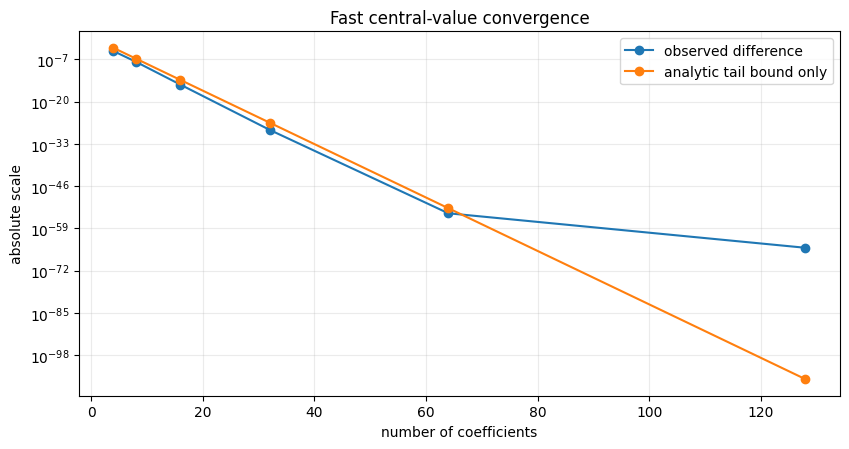

In [43]:
center_convergence = []
for M in (4, 8, 16, 32, 64, 128):
    r = lab.central_L(lab.CURVES["11a1"], N=M, dps=60)
    center_convergence.append({"M": M, "L(1)近似": mp.nstr(r["value"], 24),
                               "参照値との差": float(abs(r["value"]-central11["value"])),
                               "尾の上界": float(r["tail_bound"])})
center_convergence = pd.DataFrame(center_convergence)
display(center_convergence)
lab.plot_lines(center_convergence["M"], {"observed difference": np.maximum(center_convergence["参照値との差"], 1e-65),
               "analytic tail bound only": center_convergence["尾の上界"]},
               "Fast central-value convergence", "number of coefficients", "absolute scale", logy=True, markers=True)
plt.show()

打切り項数を増やす図では、実測差と尾の上界を比べる。差が計算精度以下になると、差そのものが0と丸められることがある。対数軸で見せるために表示下限を設けても、それを誤差が保証された桁数とは解釈しない。

例えば尾が$10^{-132}$以下でも、60桁で評価した値に132桁の正しさがあるわけではない。誤差には、係数・積分区間の打切り、数値求積、浮動小数点の丸めがある。使った式に応じて、どれを制御しどれを観察に留めるかを分ける。

## 7. L関数の零点と、BSDの二つの主張

有理点のランク$r$は群の性質である。一方、**解析的ランク**$r_{\rm an}$は$L(E,s)$の$s=1$における零点の次数である。

$$L(E,1+z)=Cz^{r_{\rm an}}+O(z^{r_{\rm an}+1}),\qquad C\ne0.$$

Birch–Swinnerton-Dyer（BSD）の予想には、まず$r=r_{\rm an}$という主張がある。二つ目は、先頭係数$C$を曲線の算術的不変量で表す公式で、第7.2節で定義する。ここでは一般の予想を証明せず、具体例で両側の情報を区別しながら調べる。

比較例は次の4曲線で、表の有理点のランクは参照データとして与える。ランクの計算結果をグラフから逆算してはいない。[ECAPI](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/ell_rational_field.html) [RANK3](https://www.lmfdb.org/EllipticCurve/Q/5077/a/1)

|名称|方程式|導手|参照ランク|
|:--|:--|--:|--:|
|11a1|$y^2+y=x^3-x^2-10x-20$|11|0|
|37a1|$y^2+y=x^3-x$|37|1|
|389a1|$y^2+y=x^3+x^2-2x$|389|2|
|5077a1|$y^2+y=x^3-7x+6$|5077|3|

$0.5\le s\le3$の実軸上で$L(E,s)$を描く。絶対値にせず符号を残すので、中心で軸を横切るか、接するかが見える。各曲線は独立した図にする。4図を並べて「見た目がそれらしい」と言うだけでなく、次に中心展開の係数を計算する。

,curve,L(-0.5),L(0),L(0.5),L(1),L(2),L(3)
0,11a1,-0.0364985179,0.0,0.1074199685,2.5384186086e-01,0.5460480362,0.7527231474
1,37a1,0.1877456635,-0.0,-0.0890486469,0.0000000000e+00,0.3815754083,0.6834342901
2,389a1,-6.4139008624,0.0,0.2099513033,-1.4792268891e-13,0.3600928636,0.6926396950
3,5077a1,279.3879452220,-0.0,-0.4920628838,0.0000000000e+00,0.3056370710,0.6638557605


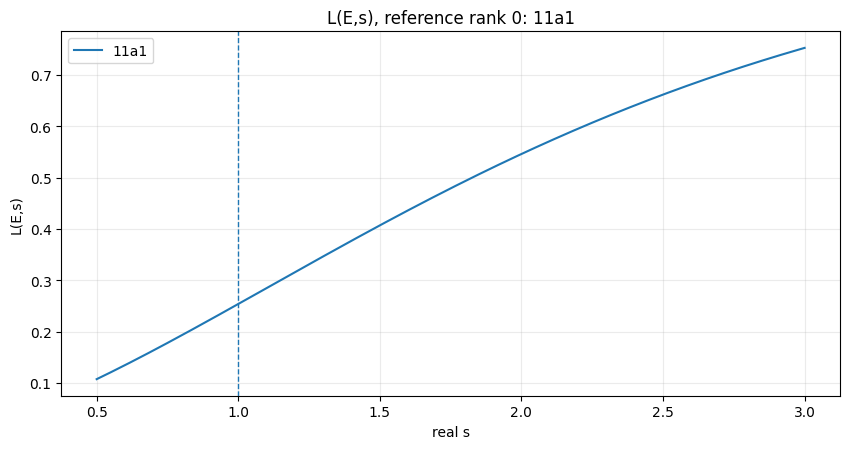

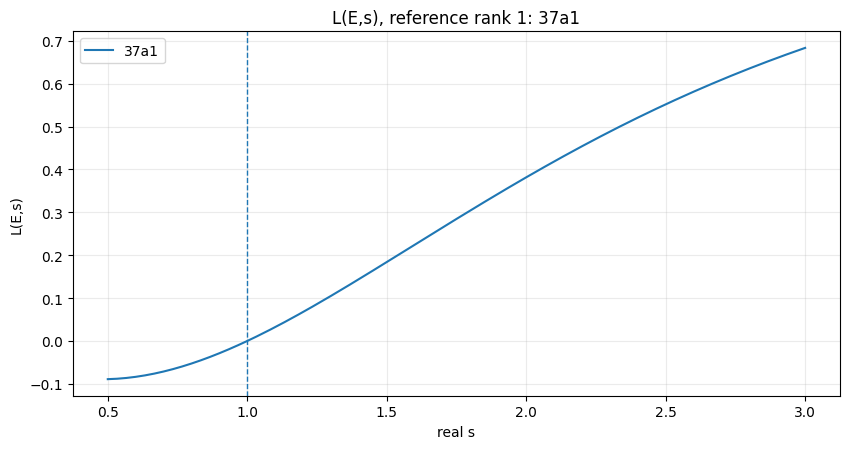

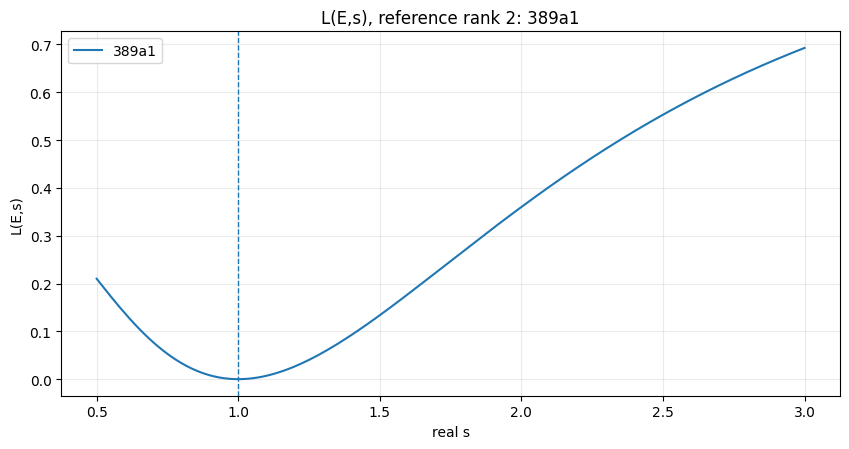

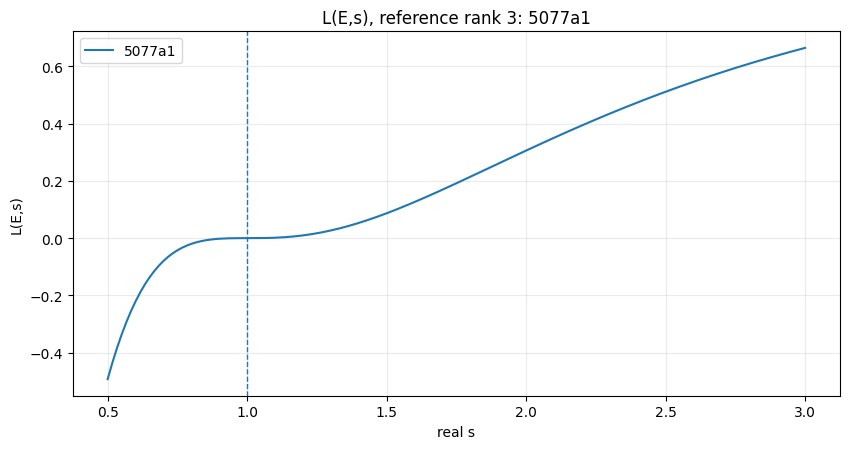

In [44]:
rank_examples = [("11a1", 0), ("37a1", 1), ("389a1", 2), ("5077a1", 3)]
quadratures = {label: lab.MellinQuadrature(lab.CURVES[label], terms=900, nodes=500) for label, rank in rank_examples}
display(pd.DataFrame([{ "curve": label, **{f"L({s})": float(quadratures[label].value(s)) for s in (-0.5,0,0.5,1,2,3)}} for label, rank in rank_examples]))
real_s = np.linspace(0.5, 3.0, 151)
for label, known_rank in rank_examples:
    vals = np.array([quadratures[label].value(float(s)) for s in real_s])
    lab.plot_lines(real_s, {label: vals}, f"L(E,s), reference rank {known_rank}: {label}", "real s", "L(E,s)")
    plt.axvline(1.0, linestyle="--", linewidth=1)
    plt.show()

### 7.1 零点の次数を調べるためのTaylor係数

$s=1+z$をMellin表示へ代入すると

$$\Lambda(E,1+z)=\int_1^\infty F(t)\big(e^{z\log t}+we^{-z\log t}\big)dt.$$

指数関数を展開し、$z^r$の係数を取れば

$$[z^r]\Lambda(E,1+z)
=\frac{1+w(-1)^r}{r!}\int_1^\infty F(t)(\log t)^r dt.$$

$w=+1$なら奇数次数、$w=-1$なら偶数次数は恒等的に0である。ただし$w=+1$でも定数項まで0になるとは限らず、$w=-1$でも1次係数まで0になるとは限らない。ランク2や3に対応する追加の消失は、係数列の非自明な相殺を伴う。

$L(E,s)=c^s\Lambda(E,s)/\Gamma(s)$で前置因子が$s=1$で非零なので、零点の次数は$L$と$\Lambda$で同じである。$r$より低い係数がすべて0なら、$L$の先頭係数は$\Lambda$の$r$次係数の$c$倍になる。この前提のもとで表には$L^{(r)}(1)/r!$の数値候補を載せる。

二つの求積条件で差も調べるが、小さな残差を強制的に0へ置き換えない。$10^{-12}$程度の数値は、厳密な零点の証明ではない。既知の参照ランクと数値的なTaylor係数は別の列に置く。

In [45]:
taylor_rows = []
for label, known_rank in rank_examples:
    Q = quadratures[label]
    finer = lab.MellinQuadrature(lab.CURVES[label], terms=1000, nodes=700)
    row = {"曲線": label, "参照ランク": known_rank}
    row.update({f"Lambdaの次数{r}係数": Q.central_coefficient(r) for r in range(4)})
    row["Lの主係数候補"] = Q.c*Q.central_coefficient(known_rank)
    row["求積変更による主係数差"] = abs(row["Lの主係数候補"]-finer.c*finer.central_coefficient(known_rank))
    taylor_rows.append(row)
taylor_table = pd.DataFrame(taylor_rows)
display(taylor_table)

,曲線,参照ランク,Lambdaの次数0係数,Lambdaの次数1係数,Lambdaの次数2係数,Lambdaの次数3係数,Lの主係数候補,求積変更による主係数差
0,11a1,0,1.3399226147e-01,0.0000000000e+00,0.0170959400,0.0000000000,0.2538418609,1.0774714454e-13
1,37a1,1,0.0000000000e+00,2.9623890870e-01,0.0000000000,0.0561695953,0.3059997738,2.1149748619e-14
2,389a1,2,-4.6433318723e-13,0.0000000000e+00,2.3835143431,0.0000000000,0.7593165003,2.8976820943e-14
3,5077a1,3,-0.0000000000e+00,-7.4295808440e-13,0.0000000000,19.6396598730,1.7318499001,2.4868995752e-14


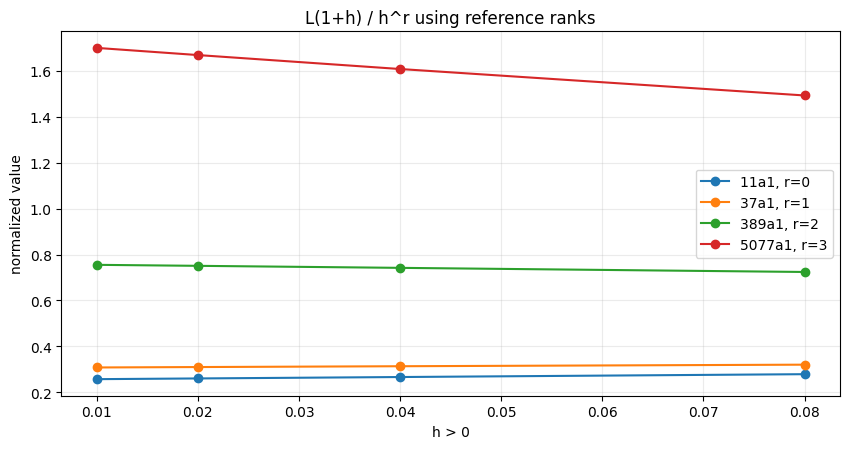

In [46]:
epsilons = [0.01, 0.02, 0.04, 0.08]
normalized = {}
for label, rank in rank_examples:
    normalized[f"{label}, r={rank}"] = [quadratures[label].value(1+h)/h**rank for h in epsilons]
lab.plot_lines(epsilons, normalized, "L(1+h) / h^r using reference ranks", "h > 0", "normalized value", markers=True)
plt.show()

$L(1+h)/h^r$の図は、参照ランク$r$を仮定した場合の先頭係数への接近を示す。ただし$h$を小さくし過ぎると、分子の丸め誤差を$h^r$で拡大する。小さい$h$ほど自動的に正確になるわけではない。

### 7.2 BSDの主係数公式を、各因子の意味から読む

BSDの主係数公式は

$$\frac{L^{(r)}(E,1)}{r!}
=\frac{|\operatorname{Sha}(E)|\,\Omega_E\,\operatorname{Reg}(E)\,\prod_p c_p}
{|E(\mathbb Q)_{\rm tors}|^2}.$$

左辺は$r$次微分そのものではなく、Taylor係数である。極の留数でもない。右辺の意味は次のとおり。

|因子|定義・役割|
|:--|:--|
|$\Omega_E$|最小モデルの不変微分$\omega=dx/(2y+a_1x+a_3)$の絶対値を、実点全体に沿って積分した量|
|$\operatorname{Reg}(E)$|自由部分の完全な基底の高さ行列の行列式。高さ対は第2.9節の規約を使い、ランク0では1とする|
|$c_p$|Tamagawa数。$E(\mathbb Q_p)$を、非特異点へ還元される部分群$E_0(\mathbb Q_p)$で割った商の位数|
|$\vert E(\mathbb Q)_{\rm tors}\vert $|無限遠点を含む有理torsion群の位数|
|$\vert \operatorname{Sha}(E)\vert $|至る所局所的に可解なtorsorの大域的障害の群の位数。公式はその有限性も含む|

良い素数では$c_p=1$なので、積は有限個の因子だけを計算すればよい。これらの量のうち、点数やtorsion位数を計算する機能はあるが、一般の$\operatorname{Sha}$やTamagawa数を自動計算する機能はない。

11a1では位数5の点を実際に作り、良い素数の還元も使って全torsionの位数5を確定できる。11における最小判別式の付値は5で、分裂乗法的還元だから$c_{11}=5$。ランク0のレギュレーターは1である。

実周期は、平方完成

$$(2y+1)^2=4x^3-4x^2-40x-79$$

を使い、右辺の唯一の実根を$r$とすると

$$\Omega_E=2\int_r^\infty\frac{dx}{\sqrt{4x^3-4x^2-40x-79}}$$

となる。$x=r+t^2$と置いて端点の平方根の特異性を取り除き、数値積分する。L関数側とは独立な実積分である。

In [47]:
assert E11.order_up_to(T11) == 5
assert E11.ap_good(2) == -2 and E11.count_mod_p(2) == 5
assert E11.ap_good(3) == -1 and E11.count_mod_p(3) == 5
omega11 = lab.real_period_one_component(E11, dps=65)
ratio11 = central11["value"]/omega11
sha_required11 = central11["value"]*25/(omega11*5)
display(pd.DataFrame({"量": ["L(E,1)", "Omega_E", "L(E,1)/Omega_E", "BSD式から逆算した |Sha|"],
                      "値": [mp.nstr(x, 35) for x in (central11["value"], omega11, ratio11, sha_required11)]}))
assert abs(ratio11-mp.mpf(1)/5) < mp.mpf("1e-48")

,量,値
0,"L(E,1)",0.25384186085591068433775892335090946
1,Omega_E,1.2692093042795534216887946167545473
2,"L(E,1)/Omega_E",0.2
3,BSD式から逆算した |Sha|,1.0


計算すると$\Omega_E\approx1.2692093042795534$、$L(E,1)/\Omega_E\approx1/5$となる。この比はSageMathの公式説明にある厳密な周期比とも整合する。[LSERIES](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/lseries_ell.html)

BSD公式へ代入すると$L(E,1)/\Omega_E=|\operatorname{Sha}|/5$なので、必要な$|\operatorname{Sha}|$は1となる。ただしこの逆算に使ったL値を、そのまま「独立に求めた$\operatorname{Sha}$と一致した」と数えるのは循環である。ここでの独立計算はL値、周期、torsionであり、$\operatorname{Sha}$の一般計算ではない。

### 7.3 合同数34と82で、周期・高さ・解析側を比べる

$E_n:y^2=x^3-n^2x$では、実数上の置換$x=nX,y=n^{3/2}Y$から微分が$1/\sqrt n$倍になる。実点の二つの成分を含めた周期は

$$\Omega_{E_n}=\frac{2\lambda}{\sqrt n},\qquad
\lambda=\tfrac12B(1/4,1/2).$$

$n=34,82$についてそれぞれ約$0.8993583214$、$0.5791156343$となる。$n=34$の点$P=(-16,120),Q=(-2,48)$から高さ行列を作り、倍点深さを4から7へ増やす。行列式は約7.10へ安定するが、単調に近づく必要はない。

解析側の追加計算に使う明示データは次である。導手はCremonaの曲線データの係数と照合できる。[DATA34](https://raw.githubusercontent.com/JohnCremona/ecdata/master/allcurves/allcurves.10000-19999) [DATA82](https://raw.githubusercontent.com/JohnCremona/ecdata/master/allcurves/allcurves.100000-109999)

|$n$|導手$N$|符号$w$|悪い素数の$a_p$|この例で用いるTamagawa積|
|--:|--:|--:|:--|--:|
|34|18496|$+1$|$a_2=a_{17}=0$|16|
|82|107584|$+1$|$a_2=a_{41}=0$|16|

符号とTamagawa積は局所計算の既知データとして与え、この実装で再計算した量には数えない。L係数はこの局所データと良い素数の点数から作る。$n=82$の中心値は指数減衰級数、$n=34$の2次係数はMellin求積で計算し、以前の数値を答えとして入力しない。

$n=34$では、点$P,Q$が張る格子の行列式を$R_{P,Q}$、自由部分におけるその指数を$I$と書くと

$$R_{P,Q}=I^2\operatorname{Reg}(E_{34}).$$

したがって、数値比$[L''(1)/2]/(\Omega R_{P,Q})$が1に近くても、BSDを前提とした解釈は$|\operatorname{Sha}|/I^2\approx1$までである。指数$I=1$を別途確認せずに$|\operatorname{Sha}|=1$を証明したことにしない。$n=82$ではランク0のレギュレーターが1なので、$L(1)/\Omega$が約4になることが、BSDの要求する$|\operatorname{Sha}|=4$と対応する。

In [48]:
P34, Q34 = E34.point(-16, 120), E34.point(-2, 48)
reg_rows = []
previous_reg = None
for depth in (4, 5, 6, 7):
    H = lab.height_pairing_matrix(E34, [P34, Q34], depth=depth)
    reg = float(np.linalg.det(H))
    reg_rows.append({"倍点深さ": depth, "点P,Qの高さ行列式": reg,
                     "一つ前の深さとの差": None if previous_reg is None else reg-previous_reg})
    previous_reg = reg
display(pd.DataFrame(reg_rows))
omega34 = 2*square_period/mp.sqrt(34)
omega82 = 2*square_period/mp.sqrt(82)
# 導手・符号・悪い素数の係数は明示入力。Tateアルゴリズムでの再計算ではない。
data34 = lab.CurveData("E34", E34, 18496, 1, ((2, 0), (17, 0)), "Cremona 18496i2; 指定局所データ")
data82 = lab.CurveData("E82", E82, 107584, 1, ((2, 0), (41, 0)), "Cremona 107584h2; 指定局所データ")
quad34 = lab.MellinQuadrature(data34, terms=2000, nodes=800)
quad34_finer = lab.MellinQuadrature(data34, terms=2400, nodes=1000)
lead34 = quad34.c*quad34.central_coefficient(2)
lead34_finer = quad34_finer.c*quad34_finer.central_coefficient(2)
center82 = lab.central_L(data82, N=3000, dps=60)
comparison34_82 = pd.DataFrame([
    {"n": 34, "Omega": mp.nstr(omega34, 18), "解析側の量": "L''(1)/2 の数値候補",
     "解析側の値": f"{lead34:.12g}", "高さ側のR": f"{previous_reg:.12g}",
     "解析値/(Omega*R)": f"{lead34/(float(omega34)*previous_reg):.12g}",
     "比のBSD解釈": "Shaの位数 / 生成格子の指数^2"},
    {"n": 82, "Omega": mp.nstr(omega82, 18), "解析側の量": "L(1)",
     "解析側の値": mp.nstr(center82["value"], 22), "高さ側のR": "1 (参照ランク0)",
     "解析値/(Omega*R)": mp.nstr(center82["value"]/omega82, 18),
     "比のBSD解釈": "Shaの位数"},
])
display(comparison34_82)
print("n=34 の中心値の残差（0へ置換しない）:", quad34.value(1))
print("n=34 の2次係数の求積条件変更差:", abs(lead34-lead34_finer))
print("n=82 の中心値の尾の上界（丸め誤差を除く）:", mp.nstr(center82["tail_bound"], 8))
assert abs(lead34-lead34_finer) < 1e-7
assert abs(center82["value"]/omega82-4) < mp.mpf("1e-20")

,倍点深さ,"点P,Qの高さ行列式",一つ前の深さとの差
0,4,7.1030505722,NaN
1,5,7.1003805949,-0.0026699772
2,6,7.0996233930,-0.0007572019
3,7,7.0996692691,0.0000458761


,n,Omega,解析側の量,解析側の値,高さ側のR,解析値/(Omega*R),比のBSD解釈
0,34,0.899358321446651195,L''(1)/2 の数値候補,6.38515195486,7.09966926912,1.0000008329,Shaの位数 / 生成格子の指数^2
1,82,0.579115634353117174,L(1),2.31646253741246869717,1 (参照ランク0),4.0,Shaの位数


n=34 の中心値の残差（0へ置換しない）: 6.1075082825352574e-12
n=34 の2次係数の求積条件変更差: 2.5774937739697634e-12
n=82 の中心値の尾の上界（丸め誤差を除く）: 2.2776323e-23


### 7.4 巨大な有理点でも、正しさは分数の等式で確認できる

$$E_{157}:y^2=x^3-157^2x$$

に対し、次の点を具体的な入力として使う。

$$x(P)=-\frac{166136231668185267540804}{2825630694251145858025},$$
$$y(P)=\frac{167661624456834335404812111469782006}{150201095200135518108761470235125}.$$

座標が大きくても、$y^2-x^3+157^2x=0$は整数・分数として厳密に確認できる。第1節の変換を使えば三辺も明示的な有理数になり、直角条件と面積157を確認できる。

このような点を最初に発見する方法と、与えられた点が正しいことを検査する方法は別である。検査にはBSDや数値的な高さの推定を仮定しない。高さの表は、この点の座標の複雑さと倍点計算の増大を観察するために付ける。

In [49]:
E157 = lab.EllipticCurve(a4=-157**2)
P157 = E157.point(F(-166136231668185267540804, 2825630694251145858025),
                 F(167661624456834335404812111469782006, 150201095200135518108761470235125))
tri157 = lab.congruent_triangle(157, P157)
assert tri157[0]**2+tri157[1]**2 == tri157[2]**2
assert tri157[0]*tri157[1]/2 == 157
display(pd.DataFrame({"辺": ["a", "b", "c"], "厳密な有理数": [str(t) for t in tri157]}))
display(pd.DataFrame(lab.height_sequence(E157, P157, depth=5)))
print("曲線上の点、直角条件、面積157をすべて分数として検証。")

,辺,厳密な有理数
0,a,411340519227716149383203/21666555693714761309610
1,b,6803298487826435051217540/411340519227716149383203
2,c,224403517704336969924557513090674863160948472041/8912332268928859588025535178967163570016480830


,n,half_height,full_height,bits
0,0,26.7335475387,53.4670950774,78
1,1,27.2574437586,54.5148875172,315
2,2,27.3001757905,54.6003515809,1261
3,3,27.3001814050,54.6003628101,5042
4,4,27.3002037549,54.6004075099,20166
5,5,27.3002867506,54.6005735012,80663


曲線上の点、直角条件、面積157をすべて分数として検証。


## 8. Frey曲線からFermatの最終定理への論理を読む

形式的なパラメータ$u,v$で

$$E_{u,v}:y^2=x(x-u)(x+v)$$

を考える。三根$0,u,-v$の差を使えば

$$\Delta_E=16u^2v^2(u+v)^2.$$

$u,v,u+v$が非零なら滑らかで、これらを割らない素数では良い還元を持つことが分かる。次のセルは判別式をSymPyで展開し、因数分解と一致することを検査する。

Fermatの最終定理との接続は、仮に互いに素な非零整数$a,b,c$と素数$p\ge5$に対して$a^p+b^p=c^p$があったとき、$u=a^p,v=b^p$を代入したFrey曲線を考えることから始まる。符号と順序を適切に取り、最小モデルで調べると、この曲線は半安定になる。半安定とは、悪い還元がすべて乗法的であることをいう。

ここで使う深い定理の役割は二つである。WilesとTaylor–Wilesの結果はこの半安定曲線の保型性を保証する。一方、Ribetのレベル下げ定理は、仮定したFermat解から来る特殊な性質を持つ曲線が保型的なら、重さ2・レベル2のcusp形式が必要になることを示す。しかし$g(X_0(2))=0$なので$S_2(\Gamma_0(2))=0$であり矛盾する。

一般の指数$n>2$は、指数4か奇素数の場合へ帰着でき、指数3と4は別の古典的な証明で処理する。ここでのコードは判別式と低レベルの次元を計算する部分を担当し、RibetやWilesの定理を計算機で再証明したとは扱わない。[MODFORMS](https://wstein.org/books/modform/modform/)

In [50]:
u, v, t = sp.symbols("u v t")
Frey_cubic = t*(t-u)*(t+v)
Frey_disc = sp.factor(16*sp.discriminant(Frey_cubic, t))
assert Frey_disc == 16*u**2*v**2*(u+v)**2
display(Math(r"\Delta_{\mathrm{Frey}}="+sp.latex(Frey_disc)))

<IPython.core.display.Math object>

### 8.1 複素指数と、Fourier級数の収束速度

$\tau=x+iy$、$y>0$に対し

$$q=e^{2\pi i\tau}=e^{-2\pi y}(\cos2\pi x+i\sin2\pi x),\qquad
|q|=e^{-2\pi y}.$$

したがって虚部が大きいほど$|q|$が小さくなり、$q^n$が速く減衰する。$y=1$では$|q|$は約0.00187である。一方、虚部が0に近づくと$|q|\to1$なので、同じ係数数でも誤差が増える。

図は$y$と$|q|$の関係を示す。基本領域への移動やFricke変換を数値計算に使う理由の一つが、この収束速度の改善にある。

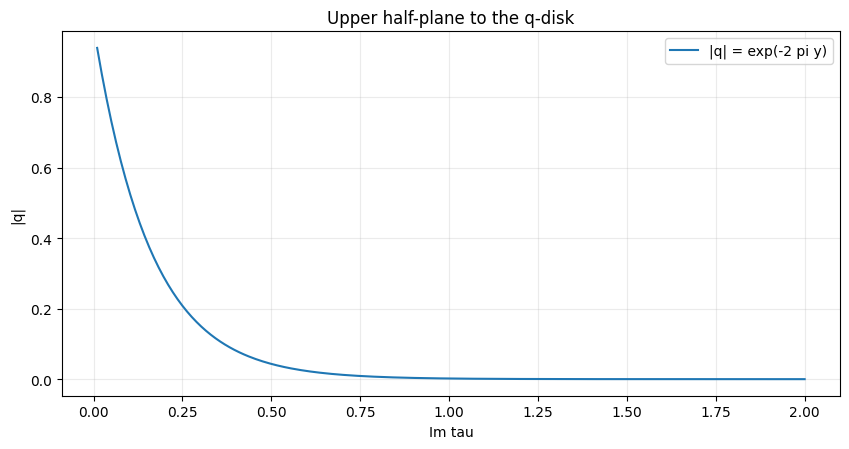

In [51]:
lab.plot_q_decay()
plt.show()

### 8.2 射影空間の点数と、四次方程式からの有理写像

$\mathbb F_p$上の射影空間$\mathbb P^d$は、$d+1$個の座標の非零ベクトルを、非零の定数倍で同一視したもの。各同値類には$p-1$個のベクトルがあるので

$$\#\mathbb P^d(\mathbb F_p)=\frac{p^{d+1}-1}{p-1}.$$

直線なら$p+1$、平面なら$p^2+p+1$である。実装は最初の非零座標を1にして代表を作り、重複を除いて数える。

四次曲線$V^2=U^4+1$に対し、$U\ne0$で

$$x=\frac{2(V+1)}{U^2},\qquad y=\frac{4(V+1)}{U^3}$$

と置くと$y^2=x^3-4x$になる。逆は、分母が非零の範囲で

$$U=\frac{2x}{y},\qquad V=\frac{2x^3}{y^2}-1.$$

式が分母0になる点では、このアフィン表示をそのまま評価せず、別の座標や滑らかな射影モデル上の延長を使う。四次式をそのまま射影平面に閉じた特異モデルと、滑らかな曲線を区別する必要がある。

また$X^3+Y^3=d$、$d\ne0$に対して

$$x=\frac{12d}{X+Y},\qquad y=\frac{36d(X-Y)}{X+Y}$$

と置けば$y^2=x^3-432d^2$となる。逆写像は$X=(36d+y)/(6x),Y=(36d-y)/(6x)$である。こうした有理写像が「楕円曲線を別の方程式として使う」方法を与える。

In [52]:
display(pd.DataFrame([
    {"p": p, "P1を直接列挙": len(lab.projective_points_fp(p, 1)),
     "P2を直接列挙": len(lab.projective_points_fp(p, 2)), "p^2+p+1": p*p+p+1}
    for p in (2, 3, 5, 7)
]))
for p in (2, 3, 5, 7):
    assert len(lab.projective_points_fp(p, 2)) == p*p+p+1
U, V = sp.symbols("U V")
xx, yy = 2*(V+1)/U**2, 4*(V+1)/U**3
numerator = sp.together(yy**2-xx**3+4*xx).as_numer_denom()[0]
assert sp.rem(numerator, V**2-U**4-1, V) == 0
display(Math(r"y^2-x^3+4x="+sp.latex(sp.factor(yy**2-xx**3+4*xx))))
X, Y, d = sp.symbols("X Y d")
xc, yc = 12*d/(X+Y), 36*d*(X-Y)/(X+Y)
cubic_residual = sp.factor(yc**2-xc**3+432*d**2)
assert sp.factor(cubic_residual-1728*d**2*(X**3+Y**3-d)/(X+Y)**3) == 0
display(Math(r"y^2-x^3+432d^2="+sp.latex(cubic_residual)))

,p,P1を直接列挙,P2を直接列挙,p^2+p+1
0,2,3,7,7
1,3,4,13,13
2,5,6,31,31
3,7,8,57,57


<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 8.3 Hensel持ち上げを1桁ずつ実装する

$f(a_k)\equiv0\pmod{p^k}$で、$f'(a_k)$がmod $p$で非零とする。

$$a_{k+1}=a_k+t p^k\qquad(t\in\{0,\ldots,p-1\})$$

と置くと、Taylor展開により

$$f(a_{k+1})\equiv f(a_k)+t p^k f'(a_k)\pmod{p^{k+1}}.$$

$f(a_k)/p^k$は整数なので、次の一桁は

$$t\equiv-\frac{f(a_k)}{p^k}\,f'(a_k)^{-1}\pmod p$$

と一意に決まる。$\sqrt2\in\mathbb Z_7$を$3^2\equiv2\pmod7$から持ち上げると、$3,10,108,2166,4567,\ldots$を得る。各値は次の値を低い法で還元したものと一致し、平方の残差が対応する$p^k$で0になる。

$f'(a_k)\equiv0\pmod p$のときには、この単純根用の関数を使えない。第3.3節の$\sqrt{41}\in\mathbb Q_2$はより一般のHensel条件で存在を示したのであって、この単純根関数が自動的に扱ったのではない。

逆数も整合する列で表せる。例えば$2^{-1}$のmod $5,25,125,625$の値は$3,13,63,313$である。

In [53]:
root7 = lab.hensel_simple(lambda a: a*a-2, lambda a: 2*a, 7, 3, depth=7)
assert root7[:5] == [3, 10, 108, 2166, 4567]
display(pd.DataFrame({"k": range(1,8), "modulus": [7**k for k in range(1,8)], "root": root7}))
display(pd.DataFrame([
    {"k": k, "modulus": 5**k, "1/2 in Z5": pow(2, -1, 5**k)} for k in range(1, 7)
]))

,k,modulus,root
0,1,7,3
1,2,49,10
2,3,343,108
3,4,2401,2166
4,5,16807,4567
5,6,117649,38181
6,7,823543,155830


,k,modulus,1/2 in Z5
0,1,5,3
1,2,25,13
2,3,125,63
3,4,625,313
4,5,3125,1563
5,6,15625,7813


### 8.4 Tate標準形で位数5の点を作る

パラメータ$b,c\in\mathbb Q$に対して

$$E(b,c):y^2+(1-c)xy-by=x^3-bx^2$$

をTate標準形という。$b=c$と置くと判別式は

$$\Delta_E=b^5(b^2-11b-1).$$

これが非零なら$(0,0)$は位数5の点になる。このようなパラメータ表示は、有理torsionを持つ曲線を系統的に作るために使える。

次のセルでは複数の有理数$b$を入れ、一般Weierstrass形の不変量から計算した判別式が上式と一致すること、$(0,0)$を5倍して$O$になり、それより前に$O$にならないことを調べる。有限個の$b$の検査は、任意の$b$についてのパラメータ表示定理の証明ではない。

In [54]:
tate_rows = []
for bpar in (F(-2), F(-1), F(1,2), F(1), F(2), F(3)):
    Eb = lab.tate_normal_form(bpar, bpar)
    disc = Eb.invariants()["discriminant"]
    order = Eb.order_up_to(Eb.point(0,0), 12)
    assert disc == bpar**5*(bpar**2-11*bpar-1)
    assert order == 5
    tate_rows.append({"b=c": str(bpar), "Delta": str(disc), "order((0,0))": order})
display(pd.DataFrame(tate_rows))

,b=c,Delta,"order((0,0))"
0,-2,-800,5
1,-1,-11,5
2,1/2,-25/128,5
3,1,-11,5
4,2,-608,5
5,3,-6075,5


## 9. 規約の違いを、実行可能な検査にする

数式が整っていても、添字や正規化を混ぜれば別の量を計算してしまう。ここまでの実験で必要な区別をまとめる。

|混同しやすいもの|採用する意味と確認方法|
|:--|:--|
|$S^2=I$か$-I$か|整数行列では$-I$、上半平面への作用では恒等|
|滑らかな実曲線と有理点の存在|実数の図だけでは有理点の存在を決めない|
|見かけの悪い還元と曲線の悪い還元|最小モデルへ移した後で判断する|
|$a_{p^2}$と$\mathbb F_{p^2}$のトレース|$a_p^2-p$と$a_p^2-2p$を分ける|
|良い素数と悪い素数のHecke作用素|$p\mid N$では$T_p=U_p$|
|曲線の$\Delta_E$と保型形式$\Delta_q$|格子モデルでは$(2\pi)^{12}$の尺度差がある|
|$a_1=1$とPeterssonノルム1|係数の正規化と内積の正規化は別|
|高さ対の$1/2$|第2.9節では前に付けず、対角は$2\widehat h(P)$|
|$E/2E$の生成元と全$E$の基底|奇数指数の不足は商だけでは検出できない|
|$\operatorname{Sha}[2]$と$\operatorname{Sha}$|2で消える部分と群全体を分ける|
|$L^{(r)}(1)$と先頭係数|先頭係数は$L^{(r)}(1)/r!$|
|小さい残差と厳密なゼロ|区間保証または厳密な議論が必要|
|関数等式を組み込んだ値と独立検証|同じ対称化式の左右の一致を二重に数えない|

### 一般の重さで、関数等式の中心を確認する

重さを$K$と書けば、Fricke関係はスケール後に$F(1/t)=w t^KF(t)$となる。第6.3節と同じ置換で

$$\Lambda(f,s)=\int_1^\infty F(t)\left(t^{s-1}+wt^{K-s-1}\right)dt,$$

したがって$\Lambda(f,s)=w\Lambda(f,K-s)$、中心は$K/2$である。楕円曲線では$K=2$なので中心1、$\Delta_q$では$K=12$なので中心6になる。

次のセルは重さ12で$s=5$と7を比較する。$s=-3$は5に対して$12-s$ではないので同じ値になる理由がない。この検査も、実装した重さの規約を確かめるためのものであり、関数等式を独立に証明するものではない。

In [55]:
S = sp.Matrix([[0,-1],[1,0]])
assert S*S == -sp.eye(2)
Avar, Bvar = sp.symbols("Avar Bvar")
translated = sp.Poly(sp.expand(Bvar**2-(1+Avar)**3+(1+Avar)), Avar, Bvar, modulus=2)
cone = sp.Poly(Bvar**2+Avar**2, Avar, Bvar, modulus=2)
assert sp.Poly((Avar+Bvar)**2, Avar, Bvar, modulus=2) == cone
assert E82.contains(lab.qpoint(82,0))
assert not E82.contains(lab.qpoint(83,0))
convention_checks = {
    "S^2": str(S*S),
    "y^2=x^3-x をmod 2で特異点へ平行移動": str(translated.as_expr()),
    "2次接錐（二本が重なる）": str(cone.as_expr()),
    "E82上か: (82,0) / (83,0)": str((E82.contains(lab.qpoint(82,0)), E82.contains(lab.qpoint(83,0)))),
    "genus(X0(37))": lab.gamma0_invariants(37)["genus"],
}
display(pd.DataFrame(convention_checks.items(), columns=["検査", "結果"]))
Lam5 = lab.modular_mellin(Deltaq, 12, 1, +1, 5, nodes=200)
Lam7 = lab.modular_mellin(Deltaq, 12, 1, +1, 7, nodes=200)
Lam_minus3 = lab.modular_mellin(Deltaq, 12, 1, +1, -3, nodes=200)
assert abs(Lam5-Lam7) < 1e-15
assert abs(Lam5-Lam_minus3) > 1e-9
display(pd.DataFrame({"s": [5,7,-3], "Lambda(Delta,s)近似": [Lam5,Lam7,Lam_minus3]}))

,検査,結果
0,S^2,"Matrix([[-1, 0], [0, -1]])"
1,y^2=x^3-x をmod 2で特異点へ平行移動,Avar**3 + Avar**2 + Bvar**2
2,2次接錐（二本が重なる）,Avar**2 + Bvar**2
3,"E82上か: (82,0) / (83,0)","(True, False)"
4,genus(X0(37)),2


,s,"Lambda(Delta,s)近似"
0,5,0.0016339860
1,7,0.0016339860
2,-3,0.0927682198


## 10. テスト、API、再現性

`run_self_tests()` は、個々の例だけでなく、不正な入力や別実装との照合も調べる。群演算では有限部分群での結合則を全列挙し、点数では総当たりと平方剰余方式を比較し、η積では直接積と再帰方式を比較する。`assert`の最適化無効化に左右されない明示的な例外で失敗を通知する。

ノートブックの後半では、主要な回帰テストを再実行し、15種類のtorsionの完全性、400係数の独立比較、64候補の完全分類も確認する。これらは、一般定理すべてを形式検証したという意味ではない。入力範囲と数学的な前提を固定した回帰検査である。

In [56]:
final_tests = lab.run_self_tests()
assert final_tests["status"] == "PASS"
assert len(lab.verify_torsion_examples()) == 15
assert f11_eta == list(lab.l_coefficients(lab.CURVES["11a1"], 400))
print(final_tests)
print("15種類のtorsion例、11の400係数、n=34の64候補の分類も全セル内で検査済み。")

{'tests': 366, 'status': 'PASS', 'seconds': 0.091}
15種類のtorsion例、11の400係数、n=34の64候補の分類も全セル内で検査済み。


### 10.1 PARI/GPによる任意の追加照合

`pari_crosscheck` は、実行環境に `gp` があれば、固定した曲線について導手・root number・最初の係数・ランクの上下限を照合する。主なコマンドは `ellglobalred`、`ellrootno`、`ellan`、`ellrank` である。[PARI](https://pari.math.u-bordeaux.fr/dochtml/html/Elliptic_curves.html)

`gp` がなければ `SKIP` を返す。主要なPython解析には不要であり、未実施の追加経路を成功したテストに数えない。導入済みの場合でも、外部プログラムの終了コードや出力形式を検査し、解釈できない出力を黙って受け入れない。

In [57]:
pari_results = [lab.pari_crosscheck(lab.CURVES[key]) for key in ("11a1", "37a1")]
display(pd.DataFrame(pari_results))

,status,reason
0,SKIP,PARI/GP の gp が未導入。主要解析には不要。
1,SKIP,PARI/GP の gp が未導入。主要解析には不要。


### 10.2 module.pyの使い方

|API|入力と戻り値|注意|
|:--|:--|:--|
|`EllipticCurve(a1,a2,a3,a4,a6)`|曲線を作る。短い形は`a4=A,a6=B`|判別式0を拒否|
|`E.point(x,y)`|検査済みの分数座標の組|曲線上にない点を拒否|
|`E.add(P,Q), E.neg(P), E.mul(n,P)`|点の和・逆元・整数倍|`None`が無限遠点|
|`E.invariants(), E.short_model()`|不変量の辞書、短い形と座標変換|短い形への変換は有理数体上|
|`E.count_mod_p(p), E.points_mod_p(p)`|点数、無限遠点を含む点集合|素数以外は拒否。特異還元も計数自体は可能|
|`E.ap_good(p)`|良い素数のトレース|悪い素数を拒否|
|`congruent_triangle(n,P,positive=True)`|三辺の分数|逆写像の検査には符号を保持|
|`tunnell_test(n)`|表現数と必要条件の判定|平方因子なしの正整数|
|`verify_torsion_examples()`|15例の生成元・位数・完全性の表|Mazurと還元の単射を前提にする|
|`height_sequence(E,P,depth)`|各倍点深さでの高さ近似と座標のビット長|保証誤差なし|
|`height_pairing_matrix(E,points,depth)`|実数の近似行列|特異性の最終判定には別の厳密計算が必要|
|`descent_delta(roots,P)`|平方類の三成分|根の順序を固定する|
|`square_class_span(generators)`|平方類群の有限生成部分群|全Selmer群を自動生成する関数ではない|
|`eta_product_coefficients(exponents,M)`|0次から$M$次までの整数係数|任意のη積の保型性を証明しない|
|`hecke_prime(a,p,k,N,M)`|$T_p$を作用させた0次から$M$次まで|入力は$pM$次まで必要|
|`CurveData(name,E,N,w,bad_ap,source)`|L計算用の明示データ|最小化・導手・符号の一般計算は行わない|
|`l_coefficients(data,M)`|0次から$M$次まで。0番は0、1番は1|局所因子の再帰を使用|
|`central_L(data,N=160,dps=60)`|値、尾の上界、項数、精度の辞書|ここでの引数`N`は導手ではなく項数|
|`MellinQuadrature(data,terms,nodes)`|`value(s)`、`completed(s)`、`central_coefficient(r)`|倍精度の数値求積|
|`completed_gamma_sum(data,s,N,dps)`|上側不完全Gammaによる完備Lの値|別経路の近似計算|
|`run_self_tests()`|件数・状態・秒数の辞書|失敗時は例外|

### 10.3 結論を読み直すための五つの問い

**なぜ分数を使うのか。** 曲線上かどうか、和が$O$かどうかは等式そのもので決めたいからである。浮動小数点を大きな精度で使うだけでは、厳密な等式の代わりにならない。

**400係数が一致すると何が分かるか。** 指定次数まで二つの独立な計算が同じ整数列を返したことが分かる。無限個の一致や保型性を結論するには、保型性定理や、所属の前提を満たしたSturm境界が必要になる。

**ランク2は数値的な観察なのか。** 合同数34の例では違う。降下法の定理、16類の有理点、残り48類の局所障害による完全分類から、$2^{r+2}=16$と決めた。L関数のグラフから推定した結果とは根拠が異なる。

**root numberが$-1$ならランク1なのか。** 完備L関数の関数等式が保証するのは解析的ランクが奇数であることまでであり、1と3などは区別しない。有理点のランクとの一致はBSDの主張や別の定理を必要とする。

**表に$\operatorname{Sha}$の整数が出たら独立計算なのか。** 既知の群構造を入力して商を計算した値、BSDから逆算した値、一般のtorsor計算で証明した値は別である。この実装はそれらを区別して表示する。

有理点の演算、局所的な点数、複素格子の周期性、保型形式の固有値、L関数の解析接続は、それぞれ異なる言語で同じ構造を扱っている。コードで数値を得るだけでなく、その数値へ至る定義と、そこから言える結論の範囲まで追うことが、この実験の目的である。

## 参考資料

リンクは定理や実装規約をさらに確認するためのものである。計算で必要な方程式・係数・局所データ・変換式は各節に明示した。追加の外部データを取得することなく、依存パッケージ導入後は主要解析を再実行できる。

- **TUNNELL**: J. B. Tunnell, *A classical Diophantine problem and modular forms of weight 3/2*, Inventiones Mathematicae 72 (1983), 323–334。必要条件と条件付きの逆向きの定理。
- **MAZUR**: B. Mazur, *Modular curves and the Eisenstein ideal*, Publications Mathématiques de l'IHÉS 47 (1977), 33–186。有理torsionの分類。
- **MODFORMS**: William Stein, *Modular Forms, A Computational Approach*。保型形式、Hecke作用素、計算的な構成の解説。
- **SQUARES / ELLIPTIC**: NIST Digital Library of Mathematical Functions, §§27.13, 23.3。平方和とWeierstrass関数。
- **ETA11**: American Institute of Mathematics, *Weight 2, Level 11*。η積の具体式。L関数の変数のシフトはここでの算術的な規約へ読み替える。
- **DIMS / CHAR / ECAPI / LSERIES**: SageMath公式リファレンス。保型形式の次元、指標、有理数体上の楕円曲線、L関数の評価。
- **DATA34 / DATA82**: John Cremonaの楕円曲線データ。係数・導手・ランク・torsionの確認に使う。該当曲線のCremonaラベルは18496i2と107584h2。
- **RANK3**: LMFDBの5077.a1。ランク3の比較曲線。
- **PARI**: PARI/GP公式マニュアルの楕円曲線API。
- **SYMPY / NBCLIENT**: SymPyの数論リファレンスとJupyter nbclientの実行API。

全リンクの確認日: 2026-10-11。

[TUNNELL](https://link.springer.com/article/10.1007/BF01389327)
[MAZUR](https://link.springer.com/article/10.1007/BF02684339)
[MODFORMS](https://wstein.org/books/modform/modform/)
[SQUARES](https://dlmf.nist.gov/27.13)
[ELLIPTIC](https://dlmf.nist.gov/23.3)
[ETA11](https://aimath.org/~aimath/WWN/rmtapplications/articles/html/8a/)
[DIMS](https://doc.sagemath.org/html/en/reference/modfrm/sage/modular/dims.html)
[CHAR](https://doc.sagemath.org/html/en/reference/modfrm/sage/modular/dirichlet.html)
[ECAPI](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/ell_rational_field.html)
[LSERIES](https://doc.sagemath.org/html/en/reference/arithmetic_curves/sage/schemes/elliptic_curves/lseries_ell.html)
[DATA34](https://raw.githubusercontent.com/JohnCremona/ecdata/master/allcurves/allcurves.10000-19999)
[DATA82](https://raw.githubusercontent.com/JohnCremona/ecdata/master/allcurves/allcurves.100000-109999)
[RANK3](https://www.lmfdb.org/EllipticCurve/Q/5077/a/1)
[PARI](https://pari.math.u-bordeaux.fr/dochtml/html/Elliptic_curves.html)
[SYMPY](https://docs.sympy.org/latest/modules/ntheory.html)
[NBCLIENT](https://nbclient.readthedocs.io/en/latest/client.html)